# Installing/importing

In [1]:
# Importing and loading necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import os
import re
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from skopt import BayesSearchCV
from sklearn.metrics import (auc, roc_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import f1_score
from skopt.space import Integer, Real, Categorical

ModuleNotFoundError: No module named 'xgboost'

In [2]:
# Load the all_filtered_tfs.csv into a dataframe
data = pd.read_csv('/scratch/by2372/Kallisto_pseudoalign_BY/Kall_filtered_tfs.csv')

# Mapper to combine sra ids and cell identity
data['SRA_state'] = data['SRA'] + "_" + data['cell_identity']

# Attach external gene name to enst id so you have isoforms seperated and also know the isoforms
data['gene_isoforms'] = data['external_gene_name'] + "_" + data['target_id']

# Create a smaller table with just the 3 columns of interest
data_filt = data[['gene_isoforms', 'tpm', 'SRA_state']]

# Pivot the smaller table to get SRA_state as column names and genes+enst ids as the columns
pivot_df = data_filt.pivot_table(index='SRA_state', columns='gene_isoforms', values='tpm').fillna(0)

# Filtering to include only cols where at least one value is 0. Just to be extra safe.
filtered_pivot_df = pivot_df.loc[:, (pivot_df == 0).any(axis=0)]

# Set to copy to avoid error
filtered_pivot_df = filtered_pivot_df.copy()

# Append the cell identity into a new column seperate from the index
filtered_pivot_df.index = filtered_pivot_df.index.astype(str)
filtered_pivot_df['cell_identity'] = [x.split('_')[1] if len(x.split('_')) == 2 else '_'.join(x.split('_')[1:]) for x in filtered_pivot_df.index]

# In the below code, comment out grouping to be cancelled
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'] == 'THP1derived_M0', 'cell_identity'] = 'M0'# Grouping all M0 macrophages together
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'M0', regex=True), 'cell_identity'] = 'M0'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'hiPSC', regex=True), 'cell_identity'] = 'hiPSC'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'Neuron', regex=True), 'cell_identity'] = 'Neuron'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'Glia', regex=True), 'cell_identity'] = 'Glia'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'NK', regex=True), 'cell_identity'] = 'NK'
#filtered_pivot_df['cell_identity'] = filtered_pivot_df['cell_identity'].str.replace(r'^3Dcorticoid_', '', regex=True) # To remove 3Dcorticoid prefix if keeping neurons seperate
#filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'^3Dcorticoid_', regex=True), 'cell_identity'] = 'Neuron' # Grouping all the neurons together
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'^cardiacfib', regex=True), 'cell_identity'] = 'CardiacFibroblast' # Grouping all the cardiac fibroblasts together
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'DC1', regex=True), 'cell_identity'] = 'DC1' # Grouping all DC2s together
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'DC2', regex=True), 'cell_identity'] = 'DC2' # Grouping all DC2s together
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'M1', regex=True), 'cell_identity'] = 'M1'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'M2', regex=True), 'cell_identity'] = 'M2'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'Monocytes', regex=True), 'cell_identity'] = 'Monocytes'
filtered_pivot_df.loc[filtered_pivot_df['cell_identity'].str.contains(r'Mesoderm', regex=True), 'cell_identity'] = 'Mesoderm'

filtered_pivot_df = filtered_pivot_df[~filtered_pivot_df['cell_identity'].str.contains("culture")]

# Count occurrences of each cell_identity
cell_identity_counts = filtered_pivot_df['cell_identity'].value_counts()

# Create a boolean mask to filter rows with cell_identity occurring more than once
mask = filtered_pivot_df['cell_identity'].isin(cell_identity_counts[cell_identity_counts > 1].index)

# Filter the DataFrame using the mask
filtered_pivot_df = filtered_pivot_df[mask]

# Display unique cell identity values
filtered_pivot_df['cell_identity'].unique()
filtered_pivot_df.to_csv('/scratch/by2372/pipeline/LogReg/Kall_filtered_pivotdf.csv', index=False)

In [3]:
filtered_pivot_df

gene_isoforms,ADNP2_ENST00000262198.9,ADNP2_ENST00000559951.5,ADNP2_ENST00000560561.1,ADNP2_ENST00000560752.5,ADNP2_ENST00000561195.1,ADNP_ENST00000349014.8,ADNP_ENST00000371602.9,ADNP_ENST00000396029.8,ADNP_ENST00000396032.8,ADNP_ENST00000621696.5,...,ZZZ3_ENST00000414381.5,ZZZ3_ENST00000433749.5,ZZZ3_ENST00000458763.2,ZZZ3_ENST00000463166.5,ZZZ3_ENST00000469944.1,ZZZ3_ENST00000474746.1,ZZZ3_ENST00000476195.5,ZZZ3_ENST00000476275.5,ZZZ3_ENST00000481346.5,cell_identity
SRA_state,,,,,,,,,,,,,,,,,,,,,
ERR7056412_hiPSC,31.7680,1.157900,0.158660,0.962752,4.59681,16.9465,0.224486,14.865400,13.51940,4.323870,...,1.114320,0.000000,0.403101,2.581540,0.000000,0.000000,0.989909,0.146767,0.426646,hiPSC
ERR7056413_hiPSC,31.3094,0.501521,0.289989,0.000000,2.11750,12.4359,0.380348,13.165400,16.65080,2.885200,...,0.000000,0.538551,0.384780,0.000000,0.000000,0.000000,1.159280,0.000000,0.656572,hiPSC
ERR7056414_hiPSC,29.5748,0.789025,0.146076,0.161029,12.04820,20.1199,0.373064,15.458400,8.76621,2.666710,...,0.439841,0.000000,0.551358,0.651545,0.108103,0.332697,0.261714,0.156665,0.851478,hiPSC
SRR12271075_Monocytes_THP1,0.0000,0.000000,0.000000,0.000000,0.00000,0.0000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Monocytes
SRR12271076_Monocytes_THP1,0.0000,0.000000,0.000000,0.000000,0.00000,0.0000,0.000000,0.000000,0.00000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,Monocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SRR6940492_primary_Glia,16.7963,0.000000,2.148950,0.000000,0.00000,23.2935,1.965290,0.000000,2.35306,0.000000,...,0.000000,8.472480,1.615450,0.000000,0.000000,0.000000,4.624730,1.916530,0.426954,Glia
SRR6940493_primary_Glia,16.6352,0.000000,1.735340,0.000000,0.00000,24.0807,4.047280,2.766100,4.94080,2.345870,...,0.000000,4.408360,5.576210,0.000000,3.281610,0.000000,4.093000,3.306080,0.000000,Glia
SRR6940494_primary_Glia,15.2840,0.000000,2.748300,0.575397,63.07620,21.4152,3.649670,1.177880,1.26868,2.278350,...,0.000000,5.037140,7.024970,5.323630,0.815008,0.000000,0.952179,5.900110,0.000000,Glia


In [4]:
cell_identity_counts

cell_identity
CardiacFibroblast    21
Neuron               18
hiPSC                17
DC2                  14
primary_Tcells       14
DC1                   9
Glia                  8
M1                    8
M0                    8
M2                    6
Monocytes             6
NK                    6
Mesoderm              6
Name: count, dtype: int64

In [5]:
filtered_pivot_df['cell_identity'].value_counts()

cell_identity
CardiacFibroblast    21
Neuron               18
hiPSC                17
DC2                  14
primary_Tcells       14
DC1                   9
Glia                  8
M1                    8
M0                    8
M2                    6
Monocytes             6
NK                    6
Mesoderm              6
Name: count, dtype: int64

# Train/Test Processing

In [6]:
# Seperate the ensmbl ids from the cell_identity column
TFs = filtered_pivot_df.columns.drop(['cell_identity'])

# Set predictors and predicted
X = np.array(filtered_pivot_df[TFs])
y = np.array(filtered_pivot_df['cell_identity'])


# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5, stratify=y)
print('y_test:', y_test)
print('y_train:', y_train)

# Checking random sampling to ensure all classes are present in both train and test groups
# Find unique labels in y_test and y_train
unique_test = set(y_test)
unique_train = set(y_train)

# Check for missing labels
missing_labels = unique_test - unique_train

# Print results
if missing_labels:
    print(f"These labels in y_test are not present in y_train: {missing_labels}")
else:
    print("All labels in y_test have at least one replicate in y_train.")

NameError: name 'train_test_split' is not defined

In [13]:
pd.Series(y_test).value_counts()

Neuron               4
CardiacFibroblast    4
DC2                  3
hiPSC                3
primary_Tcells       3
M1                   2
M0                   2
DC1                  2
Glia                 2
Monocytes            1
Mesoderm             1
M2                   1
NK                   1
Name: count, dtype: int64

In [14]:
pd.Series(y_train).value_counts()

CardiacFibroblast    17
hiPSC                14
Neuron               14
DC2                  11
primary_Tcells       11
DC1                   7
M0                    6
Glia                  6
M1                    6
Mesoderm              5
NK                    5
M2                    5
Monocytes             5
Name: count, dtype: int64

# Random Oversampler

In [15]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_train,y_train)

print("Original class distribution:", Counter(y_train))
print("Resampled class distribution:", Counter(y_ros))

Original class distribution: Counter({'CardiacFibroblast': 17, 'hiPSC': 14, 'Neuron': 14, 'primary_Tcells': 11, 'DC2': 11, 'DC1': 7, 'M0': 6, 'Glia': 6, 'M1': 6, 'Mesoderm': 5, 'NK': 5, 'M2': 5, 'Monocytes': 5})
Resampled class distribution: Counter({'hiPSC': 17, 'CardiacFibroblast': 17, 'M0': 17, 'DC1': 17, 'Neuron': 17, 'primary_Tcells': 17, 'Glia': 17, 'DC2': 17, 'Mesoderm': 17, 'NK': 17, 'M1': 17, 'M2': 17, 'Monocytes': 17})


# SMOTE

In [16]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=0,k_neighbors = 1)

X_SMOTE, y_SMOTE = smote.fit_resample(X_train,y_train)
print("Original class distribution:", Counter(y_train))
print("Resampled class distribution:", Counter(y_SMOTE))

Original class distribution: Counter({'CardiacFibroblast': 17, 'hiPSC': 14, 'Neuron': 14, 'primary_Tcells': 11, 'DC2': 11, 'DC1': 7, 'M0': 6, 'Glia': 6, 'M1': 6, 'Mesoderm': 5, 'NK': 5, 'M2': 5, 'Monocytes': 5})
Resampled class distribution: Counter({'hiPSC': 17, 'CardiacFibroblast': 17, 'M0': 17, 'DC1': 17, 'Neuron': 17, 'primary_Tcells': 17, 'Glia': 17, 'DC2': 17, 'Mesoderm': 17, 'NK': 17, 'M1': 17, 'M2': 17, 'Monocytes': 17})


# ADASYN

In [17]:
from imblearn.over_sampling import ADASYN

adasyn = ADASYN(random_state=0,n_neighbors = 1)

X_ADASYN, y_ADASYN = adasyn.fit_resample(X_train,y_train)
print("Original class distribution:", Counter(y_train))
print("Resampled class distribution:", Counter(y_ADASYN))

RuntimeError: Not any neigbours belong to the majority class. This case will induce a NaN case with a division by zero. ADASYN is not suited for this specific dataset. Use SMOTE instead.

# BorderlineSMOTE

In [18]:
from imblearn.over_sampling import BorderlineSMOTE

BLsmote = BorderlineSMOTE(random_state=1,k_neighbors = 1)

X_BLSMOTE, y_BLSMOTE = BLsmote.fit_resample(X_train,y_train)
print("Original class distribution:", Counter(y_train))
print("Resampled class distribution:", Counter(y_BLSMOTE))

Original class distribution: Counter({'CardiacFibroblast': 17, 'hiPSC': 14, 'Neuron': 14, 'primary_Tcells': 11, 'DC2': 11, 'DC1': 7, 'M0': 6, 'Glia': 6, 'M1': 6, 'Mesoderm': 5, 'NK': 5, 'M2': 5, 'Monocytes': 5})
Resampled class distribution: Counter({'hiPSC': 17, 'CardiacFibroblast': 17, 'M0': 17, 'DC1': 17, 'Neuron': 17, 'primary_Tcells': 17, 'Glia': 17, 'Mesoderm': 17, 'NK': 17, 'M1': 17, 'M2': 17, 'Monocytes': 17, 'DC2': 11})


# Find AUC score For Logreg

In [12]:
def find_auc_logreg(X_train,y_train,X_test,y_test,rand_seed):
    logistic_ctrl = LogisticRegression(
        penalty='l1',
        multi_class = "multinomial",
        solver = "saga",
        random_state=rand_seed)

    # Define the search space using skopt's space definition
    logistic_search_space = {
        'max_iter': Integer(100, 400),
        'C': Real(1e-4, 1, prior='log-uniform')
    }

    # Instantiate BayesSearchCV
    logistic_bayes = BayesSearchCV(
        estimator=logistic_ctrl,
        search_spaces=logistic_search_space,
        scoring={'AUC': 'roc_auc_ovr', 'F1': 'f1_micro'},
        refit='F1',
        n_iter=10,
        cv=5,
        random_state=rand_seed,
        n_jobs=5
    )
    
    logistic_bayes.fit(X_train,y_train)

    cell_classes = np.unique(np.concatenate((y_train, y_test)))
    # predicted probabilities of test set
    y_probs = logistic_bayes.predict_proba(X_test)
    y_pred = logistic_bayes.predict(X_test)

    # Compute macro-average F1 score (treating all classes equally)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    f1_micro = f1_score(y_test,y_pred,average = 'micro')

    # Extract optimization history
    opt_df = pd.DataFrame(logistic_bayes.cv_results_)

    # binarize the classes
    y_test_bin = label_binarize(y_test, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_probs.ravel())
    roc_auc["micro"] = auc(fpr["micro"],tpr["micro"])

    #plotting
    %matplotlib inline
    plt.figure(figsize = (10,8))
    lw = 2
    plt.plot(fpr["micro"],tpr["micro"],
            label = "Micro-average ROC curve (area = {0:0.2f})".format(roc_auc["micro"]),
            color = 'deeppink', linestyle = ':', linewidth=4)

    #cycle through colors for each class
    colors = itertools.cycle(['aqua','darkorange','cornflowerblue','red','green','blue','black'])
    for class_label, color in zip(cell_classes, colors):
        plt.plot(fpr[class_label],tpr[class_label],color=color,lw=lw,
                label='ROC curve of class {0} (area = {1:0.2f})'.format(class_label,roc_auc[class_label]))

    plt.plot([0,1],[0,1],'k--',lw=lw)
    plt.xlim([0.0,1.0])
    plt.ylim([0.0,1.05])
    plt.xlabel("False Postive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend(loc="lower right")
    plt.show()

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc["micro"],
    "roc_auc_per_class": roc_auc,
    "best_score": logistic_bayes.best_score_,
    "best_params": logistic_bayes.best_params_,
    "opt_history": opt_df
    }

# Run 5 random seeds and compile metrics function

In [13]:
def multiple_seeds(auc_classifier,X_train,y_train,X_test,y_test):
    
    rand_seeds = [35,59,77,88,101]

    compiled_dicts = []

    for x in rand_seeds:

        seed_dict = auc_classifier(X_train,y_train,X_test,y_test,x)
        compiled_dicts.append(seed_dict)

    return compiled_dicts

# Export Test outputs to desired directories

In [14]:
def save_outputs(compiled_dicts,test_name):

    metrics_keys = ['f1_macro','f1_weighted','f1_micro','roc_auc_micro','best_score']
    param_key ='best_params'
    auc_key = 'roc_auc_per_class'
    opt_key = 'opt_history'

    length_list = list(range(1,len(compiled_dicts)+1))
    colnames = ["Seed " + str(num) for num in length_list]

    metrics_final = []
    param_final = []
    auc_final = []
    
    for index, dict in enumerate(compiled_dicts):

        metrics_dict_x = {k: v for k, v in dict.items() if k in metrics_keys}
        metrics_df_x = pd.DataFrame.from_dict(metrics_dict_x, orient='index')
        metrics_df_x.columns = [colnames[index]]
        metrics_final.append(metrics_df_x)

        param_dict_x = {k: v for k, v in dict.items() if k == param_key}
        param_df_x = pd.DataFrame.from_dict(param_dict_x, orient='columns')
        param_df_x.columns = [colnames[index]]
        param_final.append(param_df_x)

        auc_dict_x = {k: v for k, v in dict.items() if k == auc_key}
        auc_df_x = pd.DataFrame.from_dict(auc_dict_x, orient='columns')
        auc_df_x.columns = [colnames[index]]
        auc_final.append(auc_df_x)

        opt_dict_x = {k: v for k, v in dict.items() if k == opt_key}
        opt_df_x = opt_dict_x[opt_key]
        opt_path_x = "/scratch/by2372/pipeline/LogReg/Opt_balancing_results/" + test_name + "_" + str(index+1) + "_opt.csv"
        opt_df_x.to_csv(opt_path_x, index = True)

    metrics_final_df = pd.concat(metrics_final, axis = 1)
    param_final_df = pd.concat(param_final,axis = 1)
    auc_final_df = pd.concat(auc_final,axis = 1)

    
    metrics_path = "/scratch/by2372/pipeline/LogReg/Opt_balancing_results/" + test_name + "_metrics.csv"
    metrics_final_df.to_csv(metrics_path, index = True)

    param_path = "/scratch/by2372/pipeline/LogReg/Opt_balancing_results/" + test_name + "_param.csv"
    param_final_df.to_csv(param_path, index = True)

    auc_path = "/scratch/by2372/pipeline/LogReg/Opt_balancing_results/" + test_name + "_roc.csv"
    auc_final_df.to_csv(auc_path, index = True)

        


# AUC of unbalanced data

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.72
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.97
AUC for class primary_Tcells: 1.00


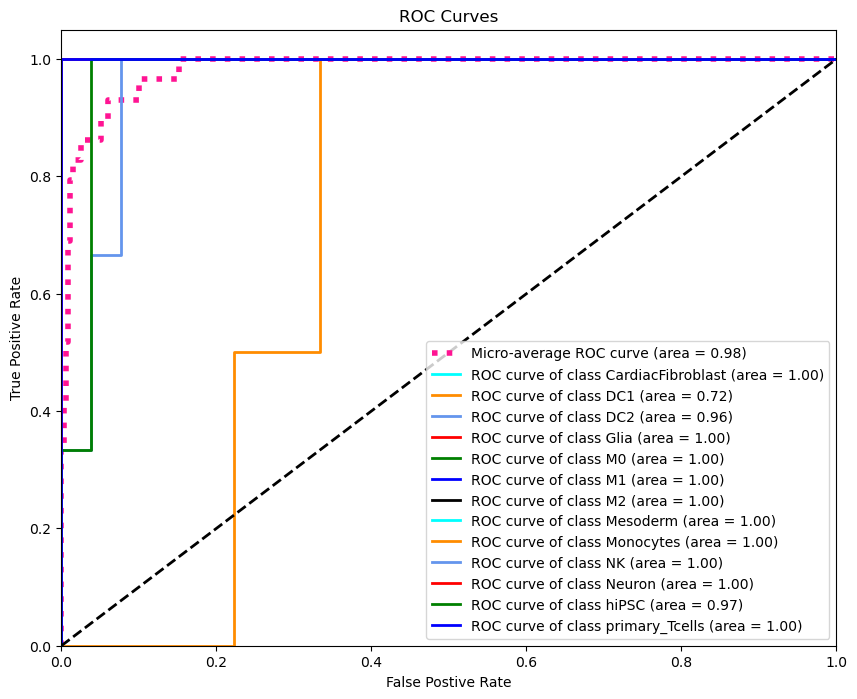

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.72
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.97
AUC for class primary_Tcells: 1.00


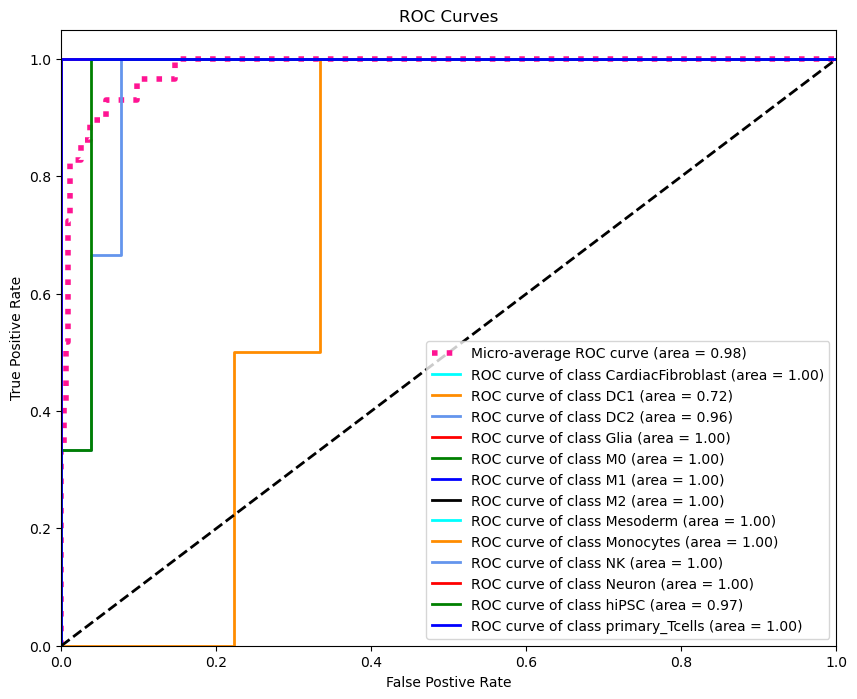

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.72
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.97
AUC for class primary_Tcells: 1.00


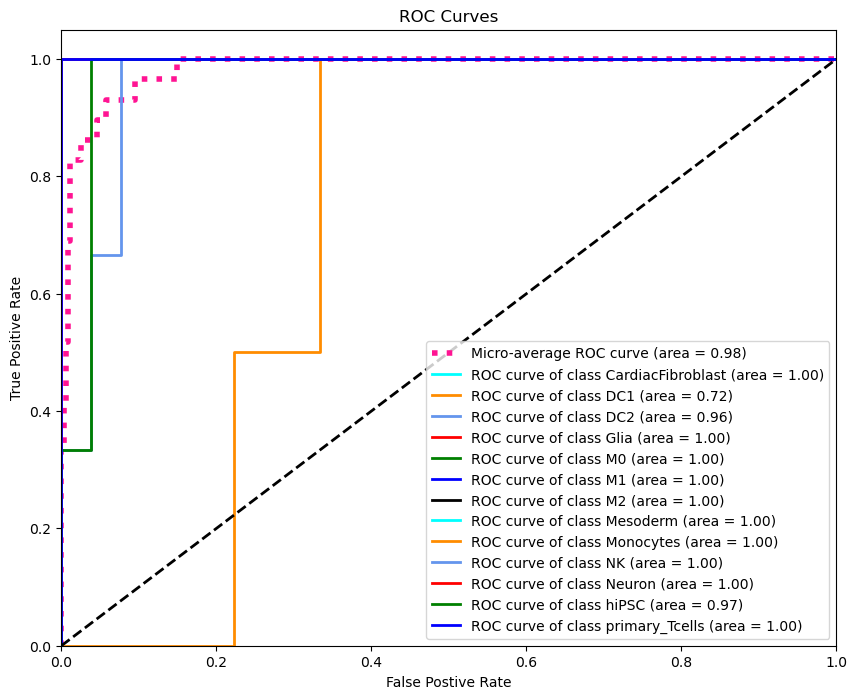

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.72
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.97
AUC for class primary_Tcells: 1.00


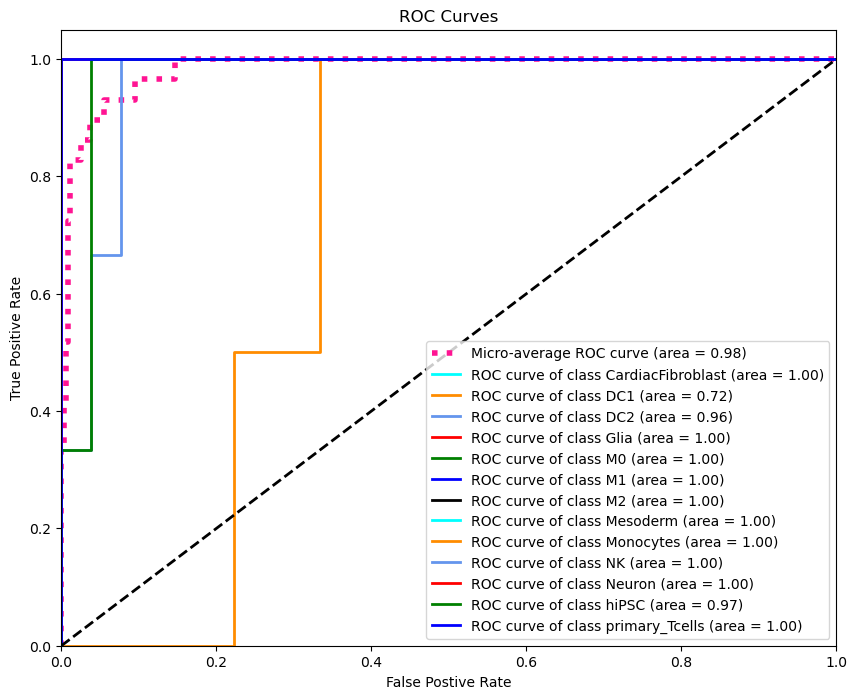

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.70
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.97
AUC for class primary_Tcells: 1.00


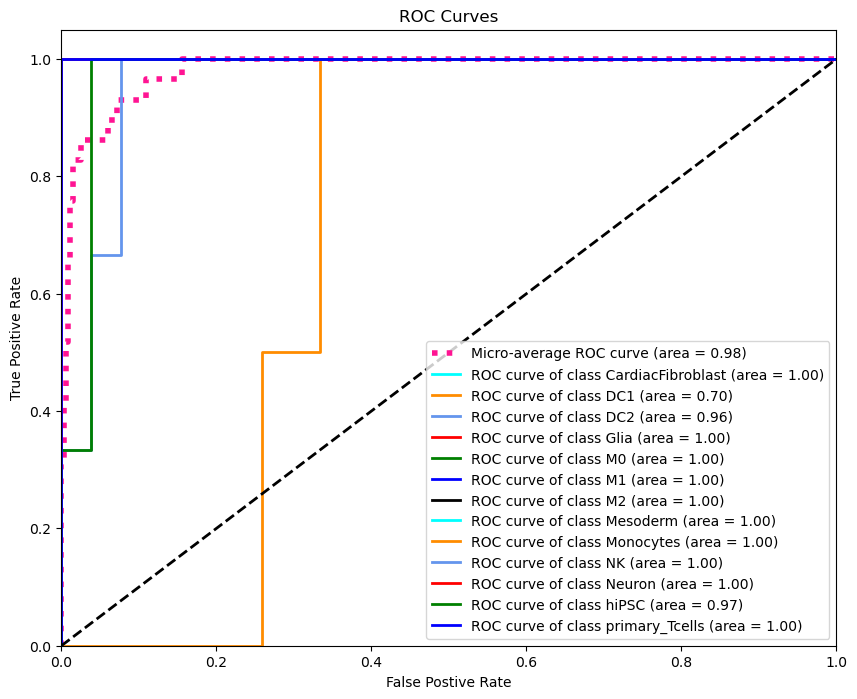

In [15]:
logreg_unbal = multiple_seeds(find_auc_logreg,X_train,y_train,X_test,y_test)

In [16]:
save_outputs(logreg_unbal,"logreg_unbal")

# AUC of RandomOversampler Data

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.99
AUC for class primary_Tcells: 1.00


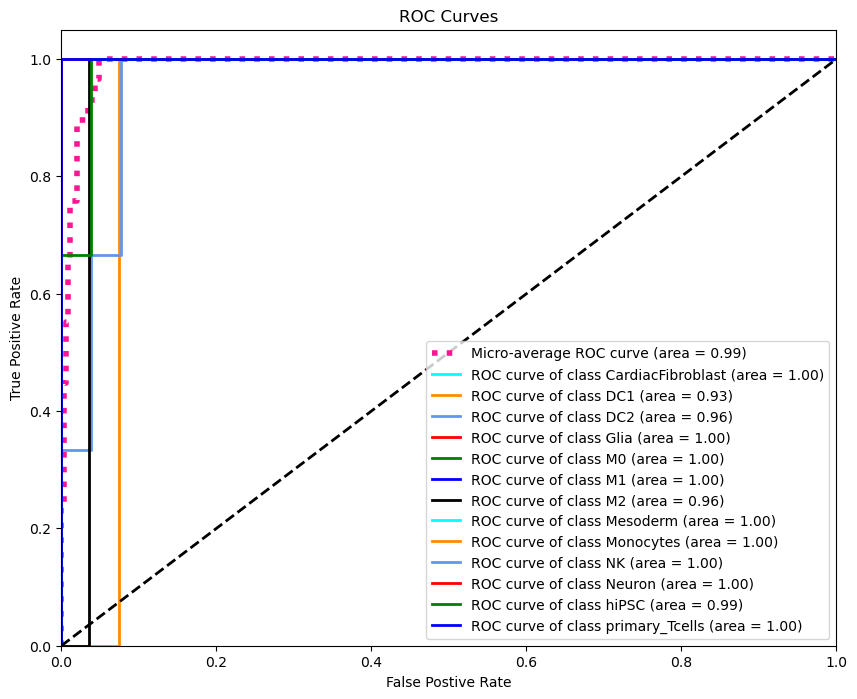

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


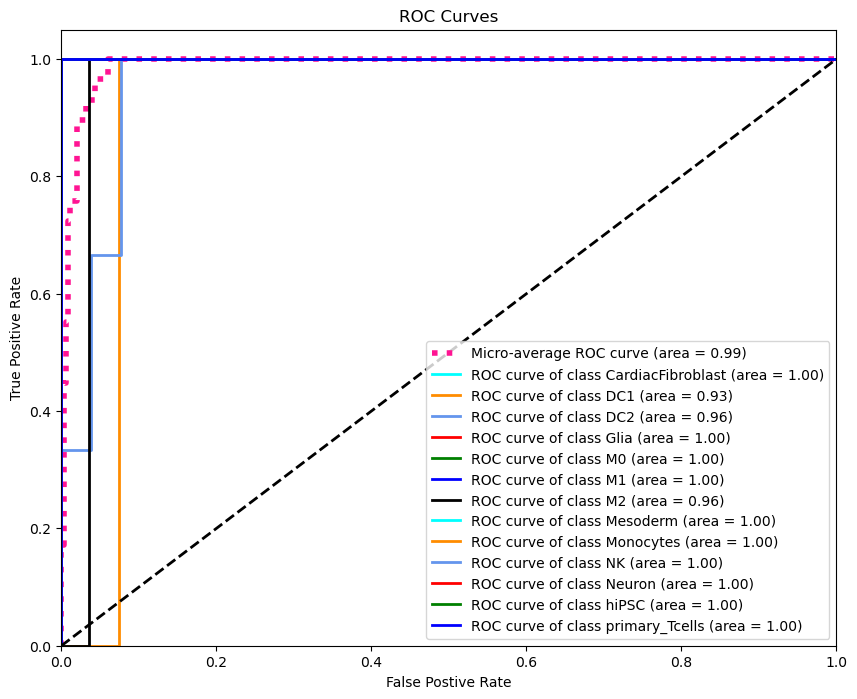

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.99
AUC for class primary_Tcells: 1.00


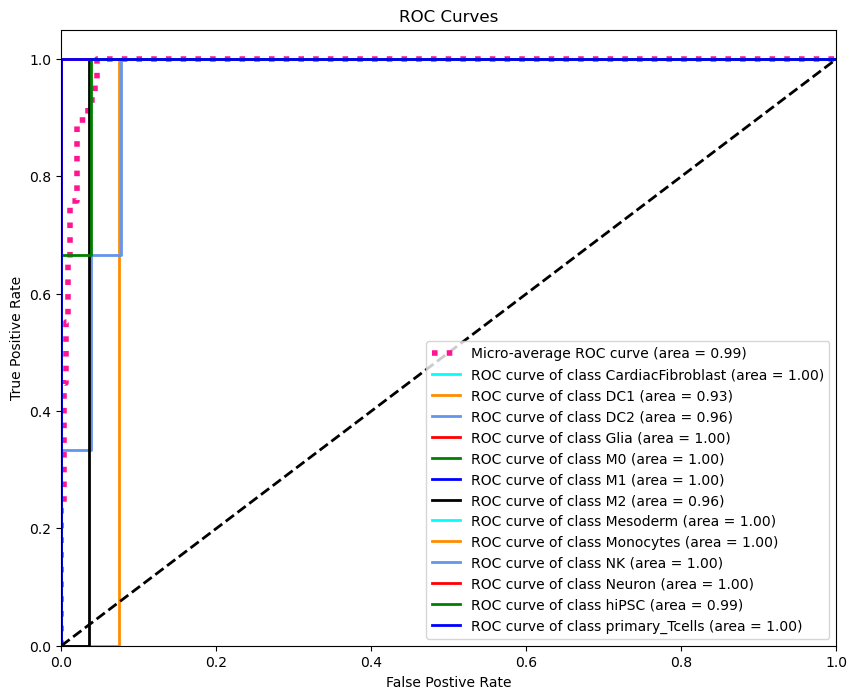

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.99
AUC for class primary_Tcells: 1.00


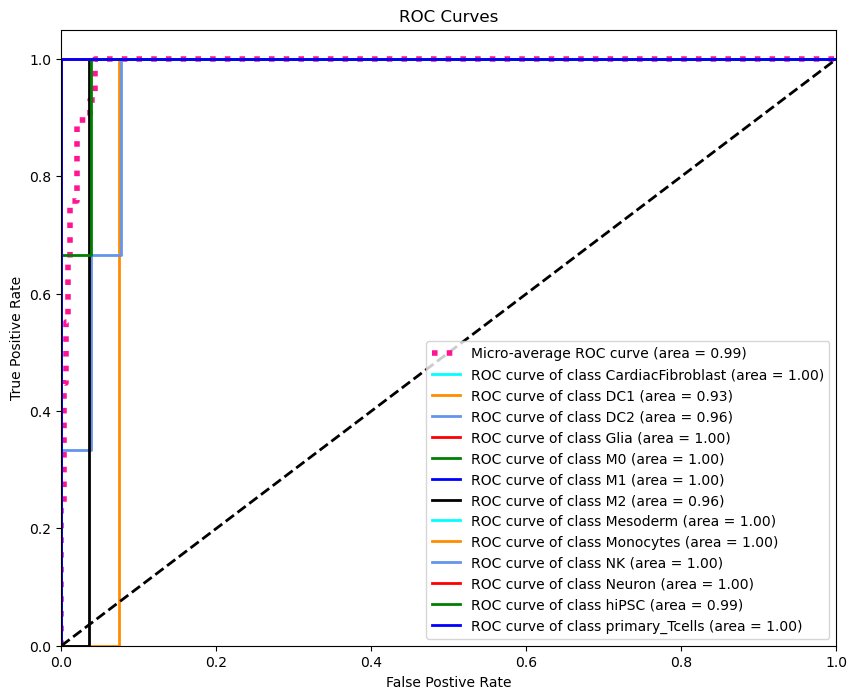

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 0.99
AUC for class primary_Tcells: 1.00


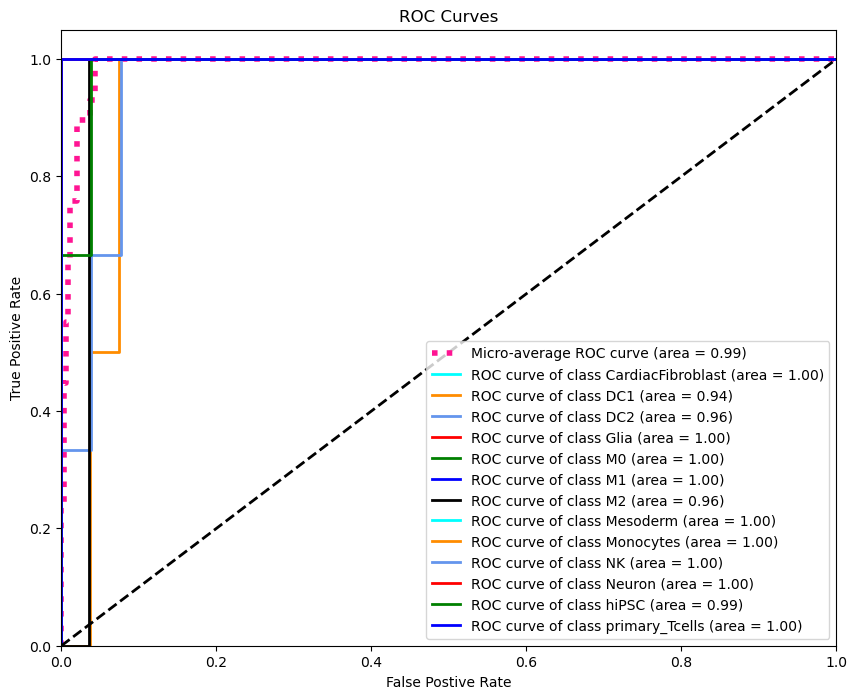

In [17]:
logreg_RO = multiple_seeds(find_auc_logreg,X_ros,y_ros,X_test,y_test)

In [18]:
save_outputs(logreg_RO,"logreg_RO")

# AUC of SMOTE

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


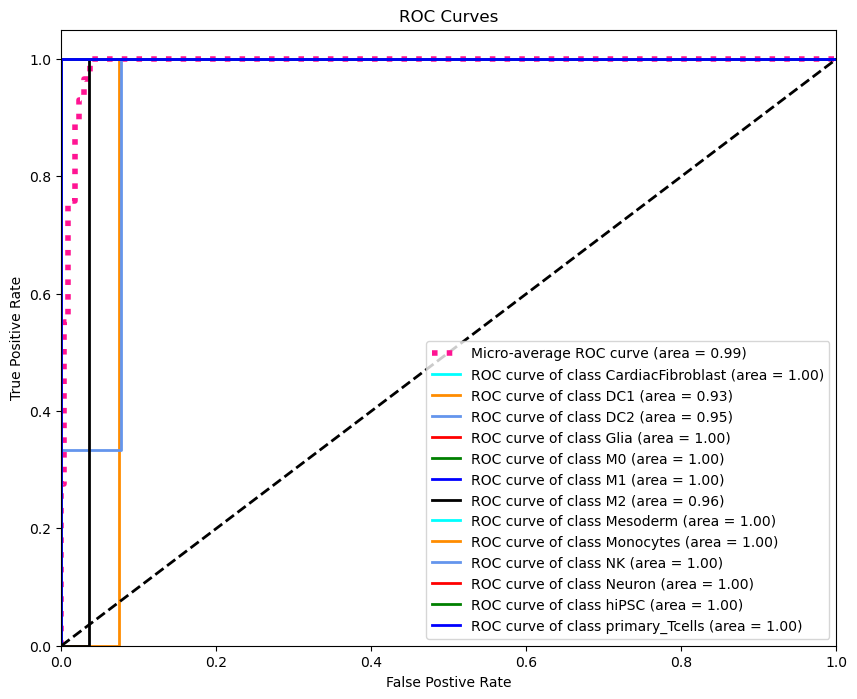

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


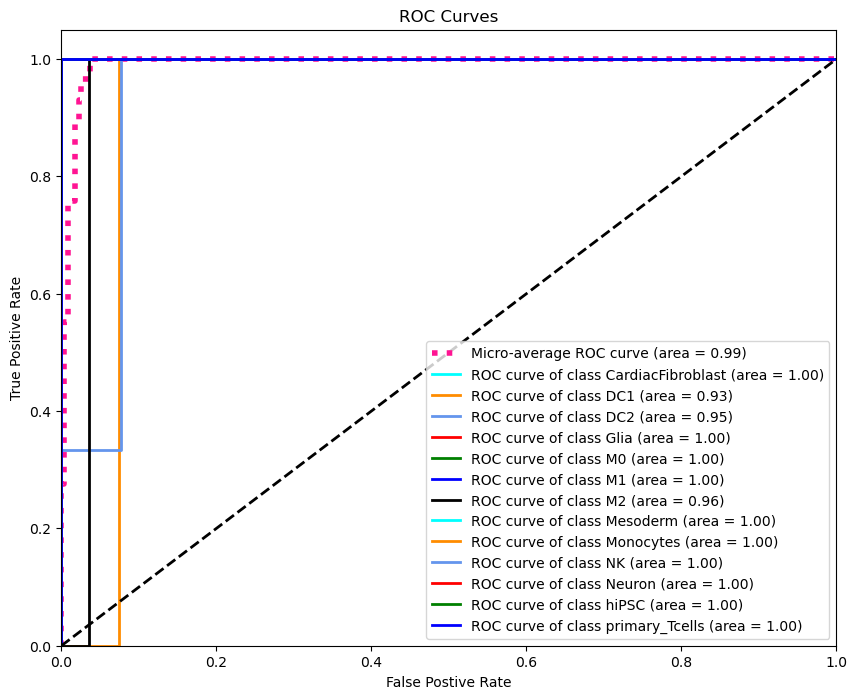

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


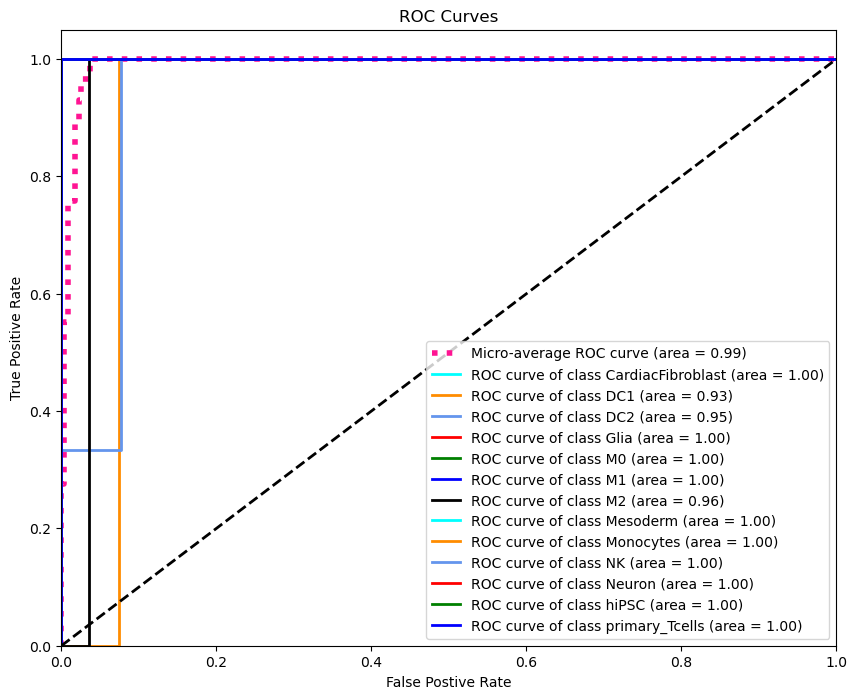

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.91
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


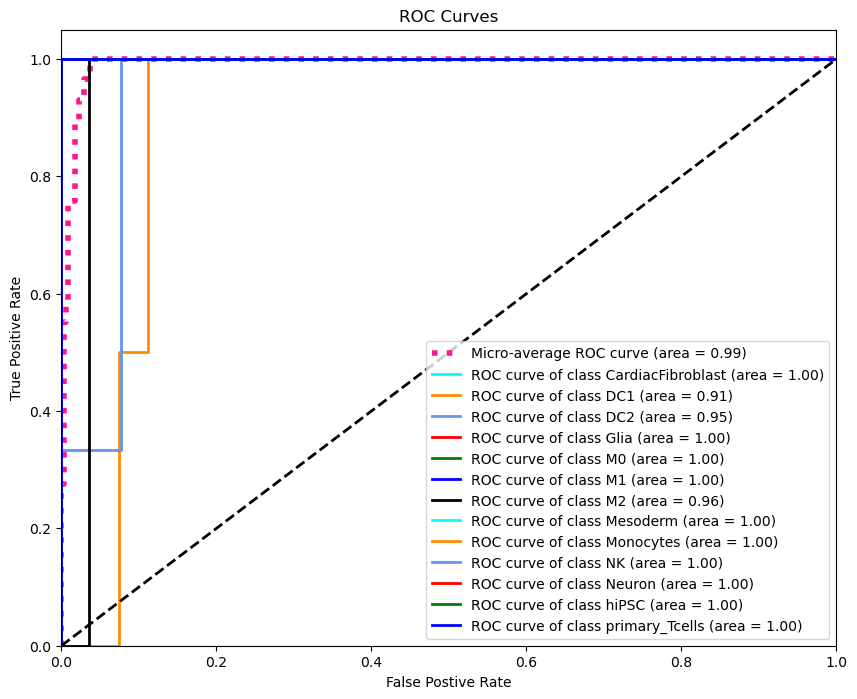

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.91
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


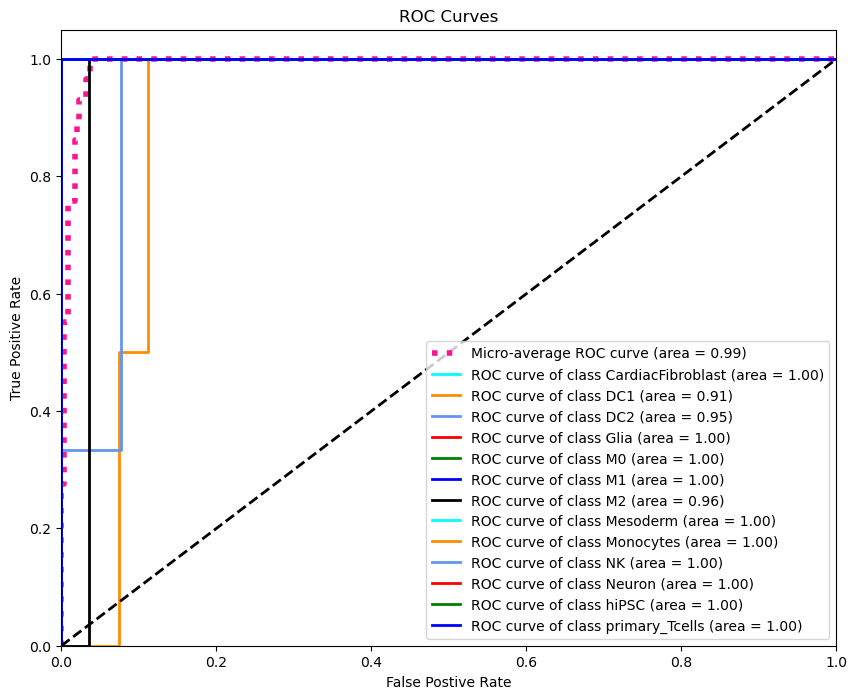

In [15]:
logreg_SMOTE = multiple_seeds(find_auc_logreg,X_SMOTE,y_SMOTE,X_test,y_test)

In [16]:
save_outputs(logreg_SMOTE,"logreg_SMOTE")

# AUC of BorderlineSMOTE

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


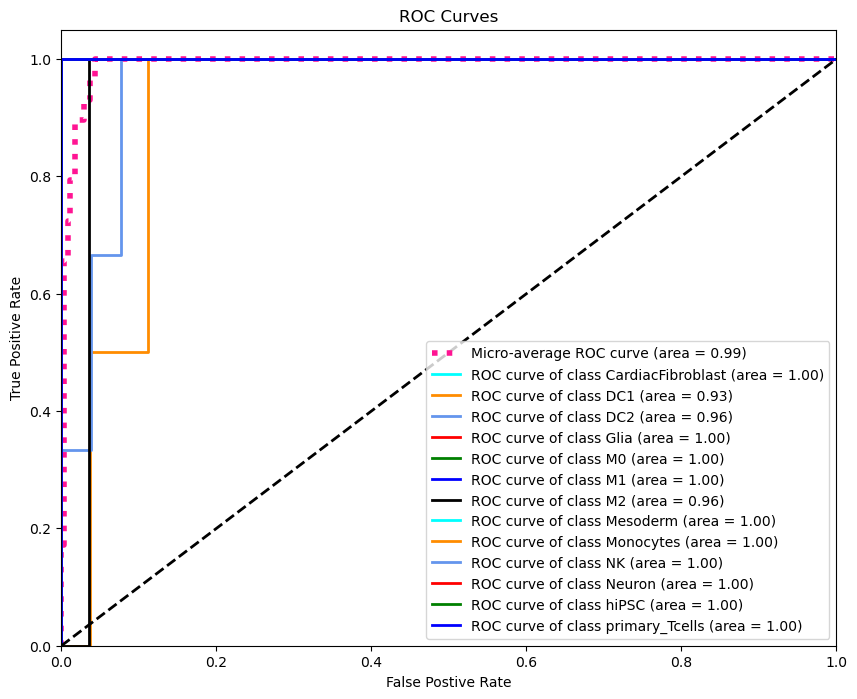

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


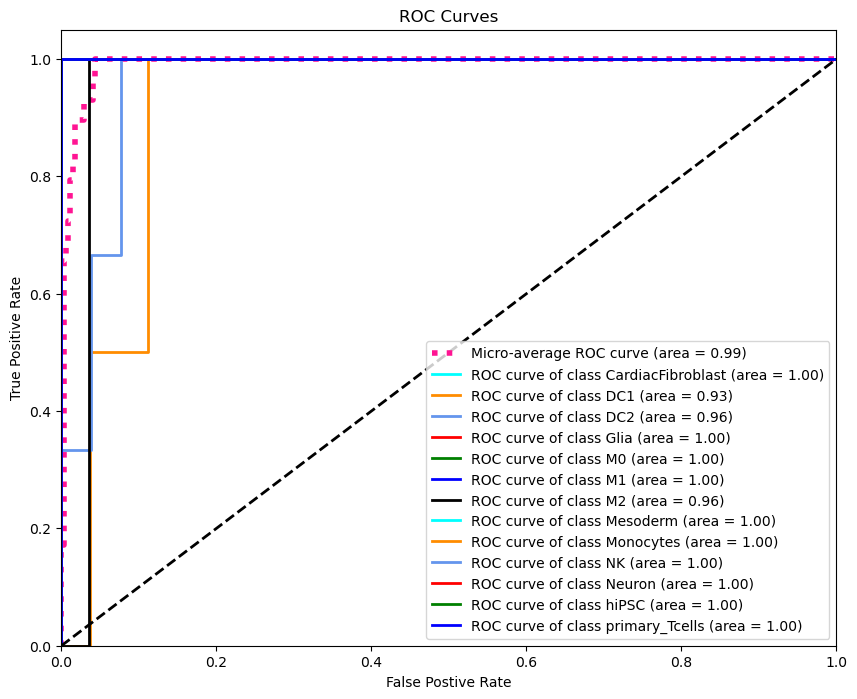

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


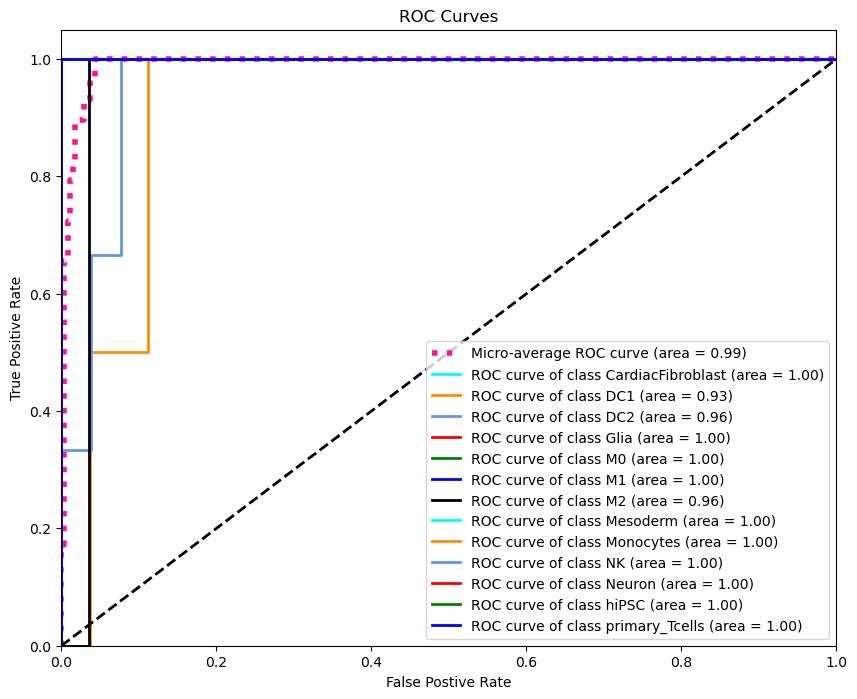

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


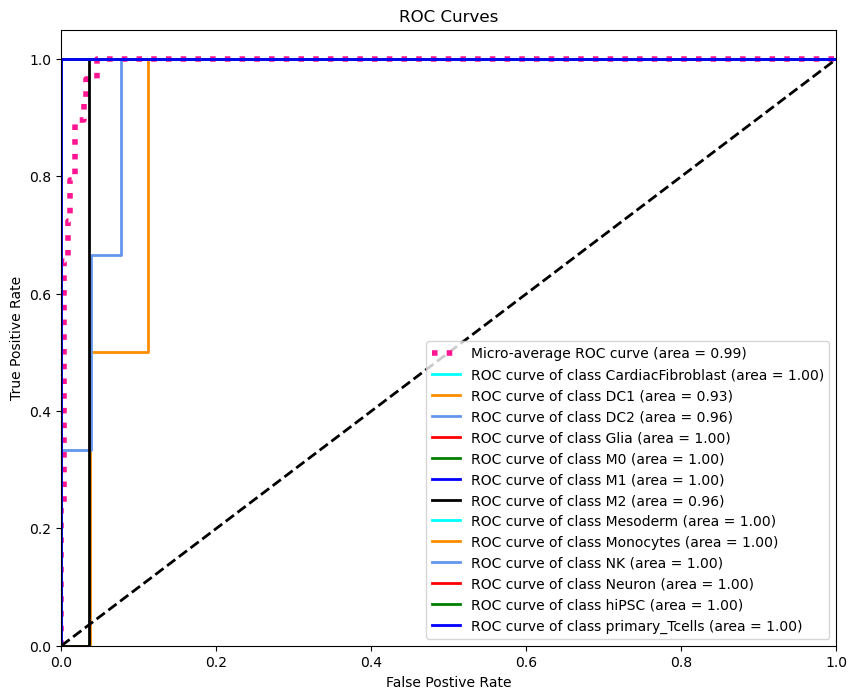

/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/share/apps/anaconda3/2024.02/

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 0.96
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


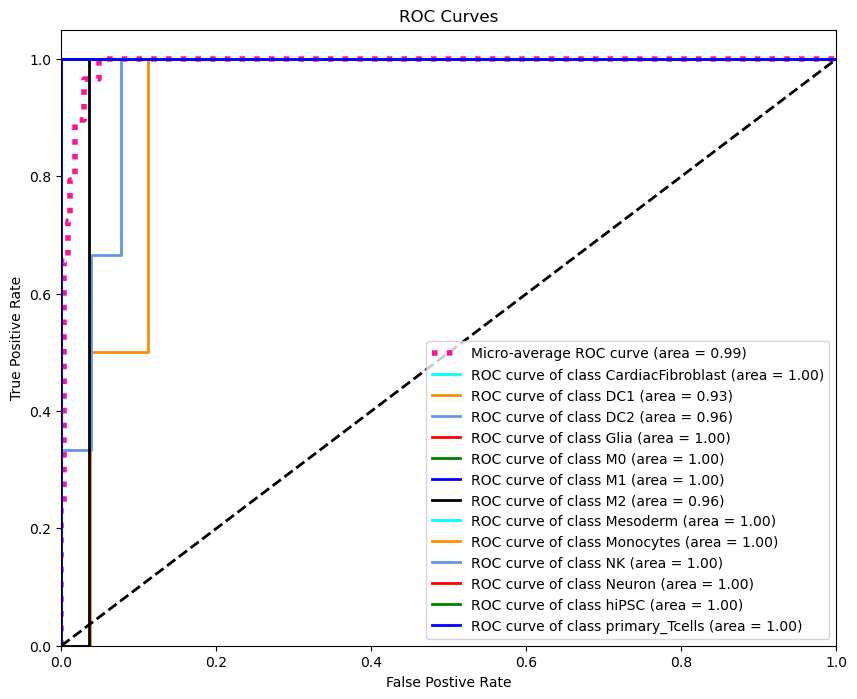

In [17]:
logreg_BLSMOTE = multiple_seeds(find_auc_logreg,X_BLSMOTE,y_BLSMOTE,X_test,y_test)

In [18]:
save_outputs(logreg_BLSMOTE,"logreg_BLSMOTE")

# Find AUC Score for Random Forest

In [19]:
def find_auc_rf(X_train,y_train,X_test,y_test,rand_seed):
    rf = RandomForestClassifier(
        criterion = "gini",
        bootstrap=True,
        random_state = rand_seed,
    )
    # Define the search space using skopt's space definition
    rf_search_space = {
        'max_depth': (5, 10),  # continuous range interpreted as integers
        'n_estimators': (100, 400),  # continuous range, also as integers
        'max_features': (0.4, 0.8, 'uniform')  # uniform float sampling between 0.2 and 0.8
    }

    # Instantiate BayesSearchCV
    rf_bayes = BayesSearchCV(
        estimator=rf,
        search_spaces=rf_search_space,
        scoring={'AUC': 'roc_auc_ovr', 'F1': 'f1_micro'},
        refit='F1',
        n_iter=10,
        cv=5,
        random_state=rand_seed,
        n_jobs=5
    )

    # Fit the model
    rf_bayes.fit(X_train, y_train)

    cell_classes = np.unique(np.concatenate((y_train, y_test)))
    # predicted probabilities of test set
    y_probs = rf_bayes.predict_proba(X_test)
    y_pred = rf_bayes.predict(X_test)
    
    # Compute macro-average F1 score (treating all classes equally)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    f1_micro = f1_score(y_test,y_pred,average = 'micro')

    # Extract optimization history
    opt_df = pd.DataFrame(rf_bayes.cv_results_)
    
    # binarize the classes
    y_test_bin = label_binarize(y_test, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_probs.ravel())
    roc_auc["micro"] = auc(fpr["micro"],tpr["micro"])

    #plotting
    %matplotlib inline
    plt.figure(figsize = (10,8))
    lw = 2
    plt.plot(fpr["micro"],tpr["micro"],
            label = "Micro-average ROC curve (area = {0:0.2f})".format(roc_auc["micro"]),
            color = 'deeppink', linestyle = ':', linewidth=4)

    #cycle through colors for each class
    colors = itertools.cycle(['aqua','darkorange','cornflowerblue','red','green','blue','black'])
    for class_label, color in zip(cell_classes, colors):
        plt.plot(fpr[class_label],tpr[class_label],color=color,lw=lw,
                label='ROC curve of class {0} (area = {1:0.2f})'.format(class_label,roc_auc[class_label]))

    plt.plot([0,1],[0,1],'k--',lw=lw)
    plt.xlim([0.0,1.0])
    plt.ylim([0.0,1.05])
    plt.xlabel("False Postive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend(loc="lower right")
    plt.show()

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc["micro"],
    "roc_auc_per_class": roc_auc,
    "best_score": rf_bayes.best_score_,
    "best_params": rf_bayes.best_params_,
    "opt_history": opt_df
    }

# AUC of Unbalanced Data Using Random Forest

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


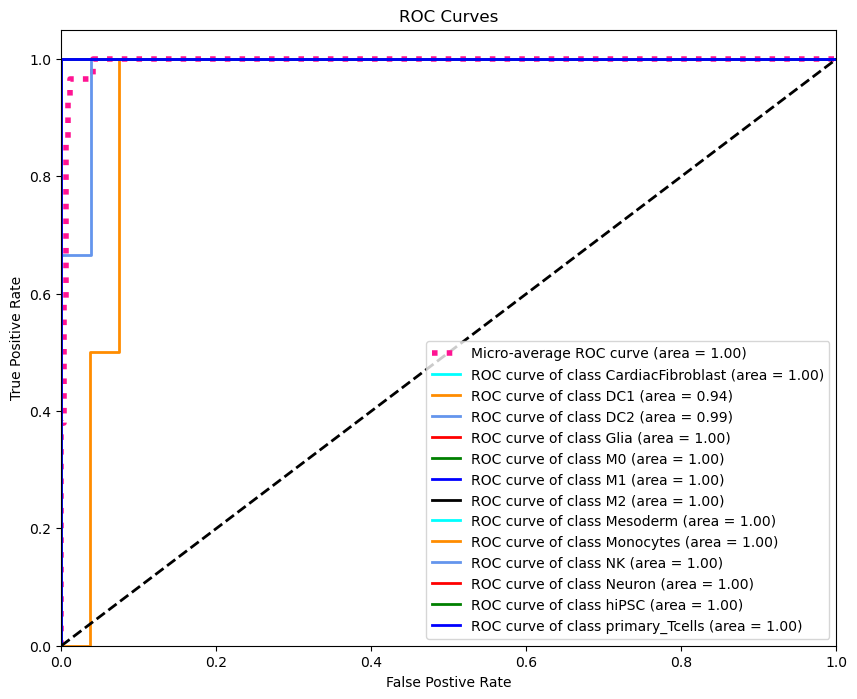

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.96
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


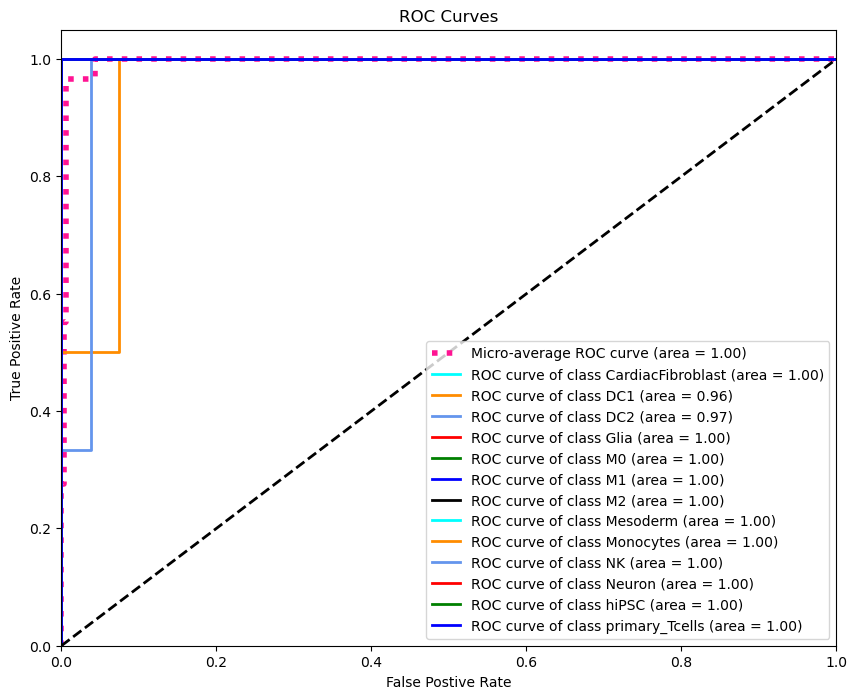

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.78
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


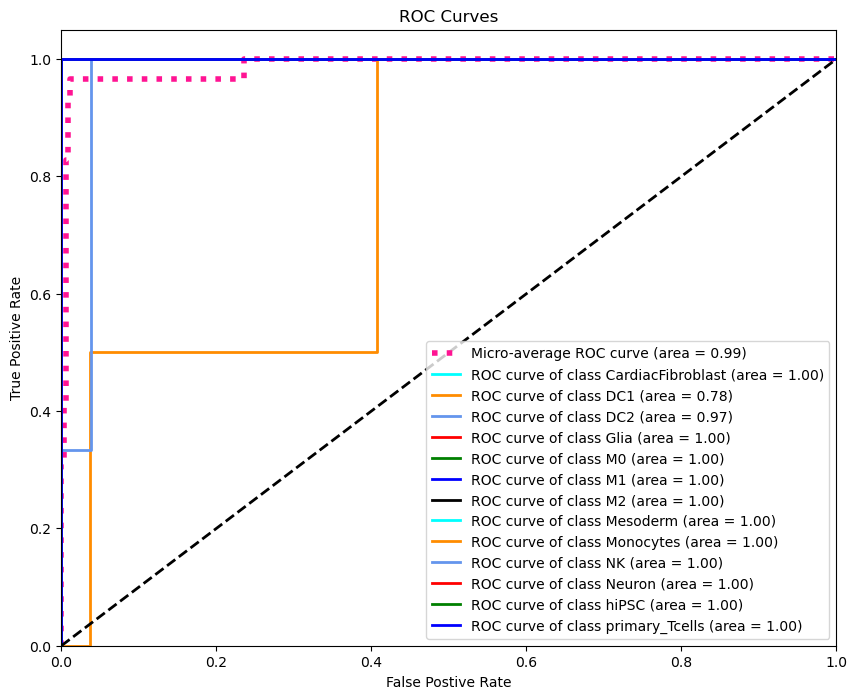

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.96
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


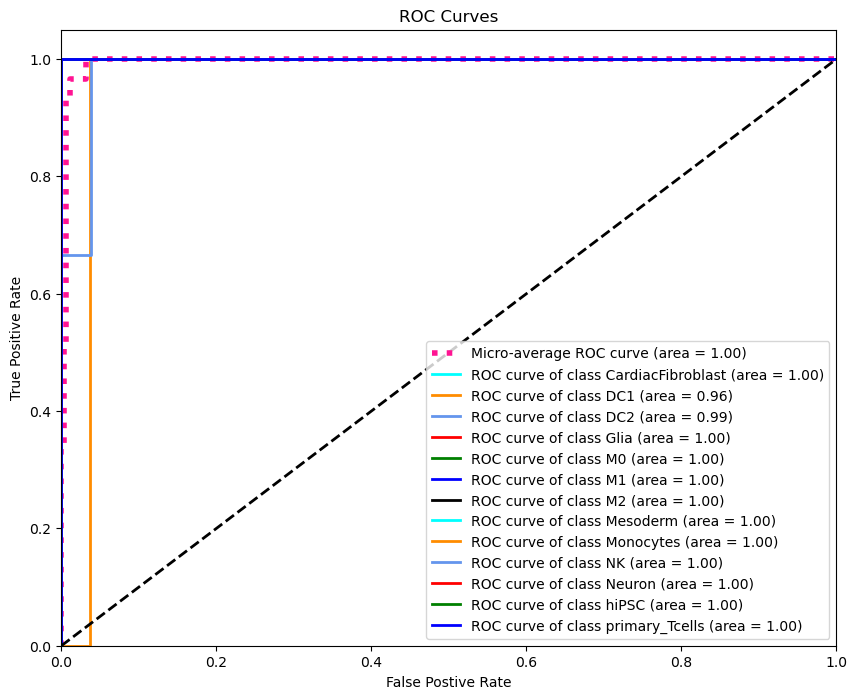

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.96
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


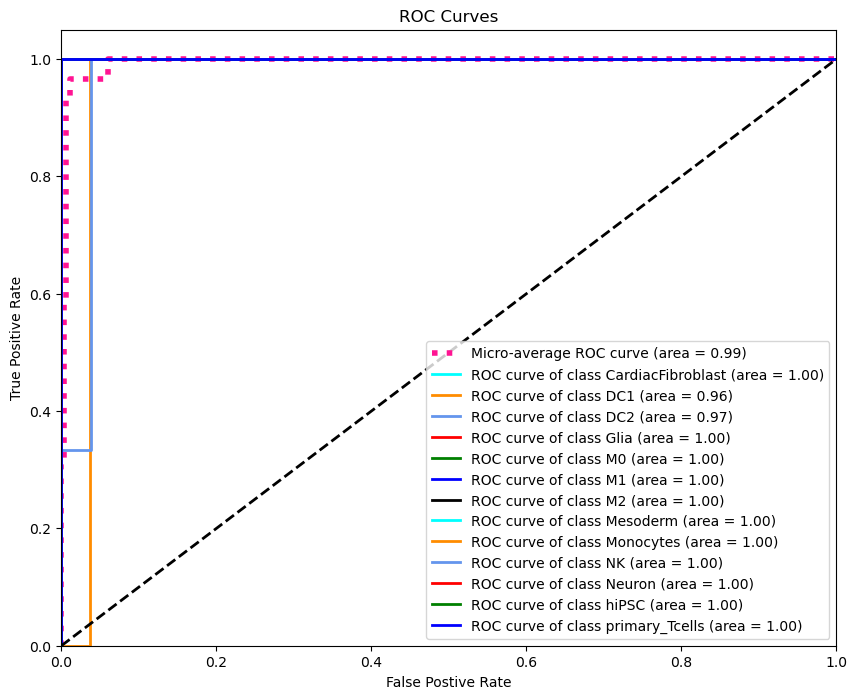

In [20]:
Randfor_unbal = multiple_seeds(find_auc_rf,X_train,y_train,X_test,y_test)

In [21]:
save_outputs(Randfor_unbal,"Randfor_unbal")

# AUC of Random Oversampler Using Random Forest

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


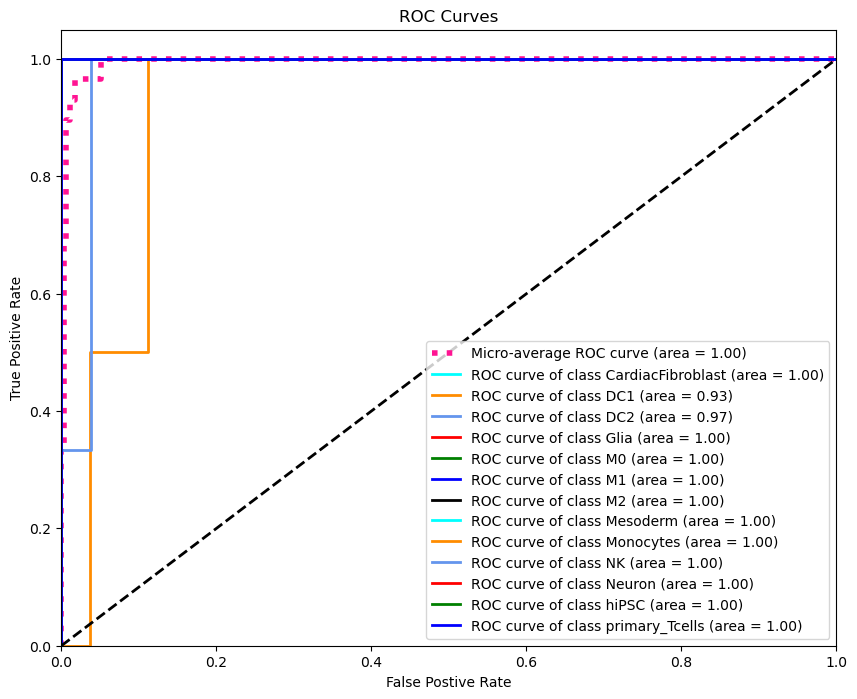

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


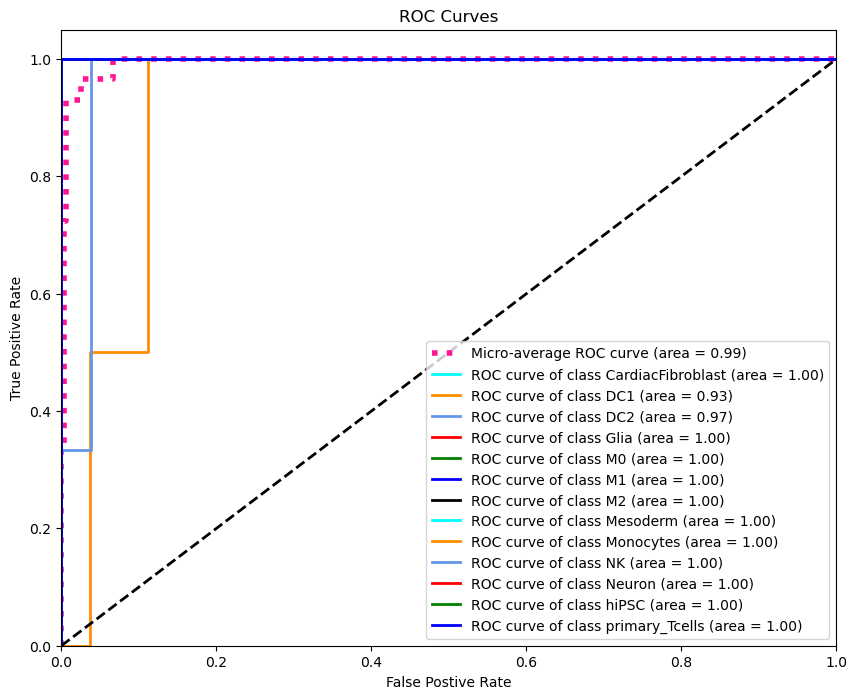

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


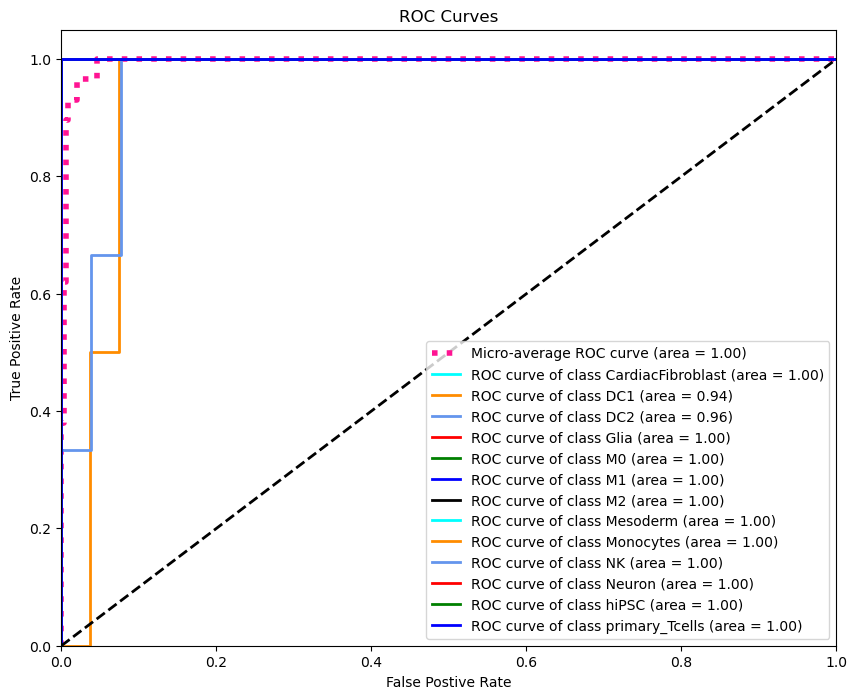

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


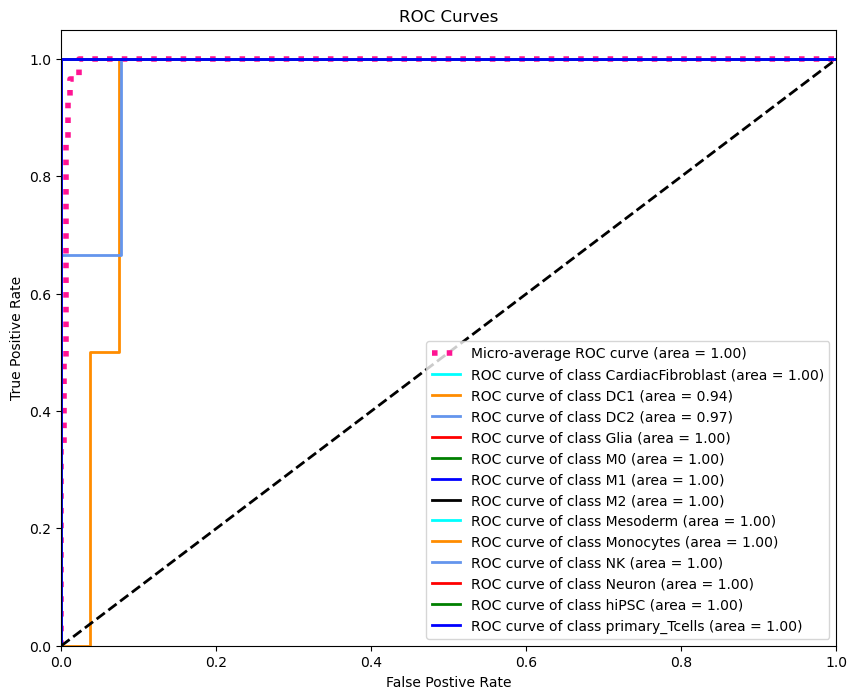

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


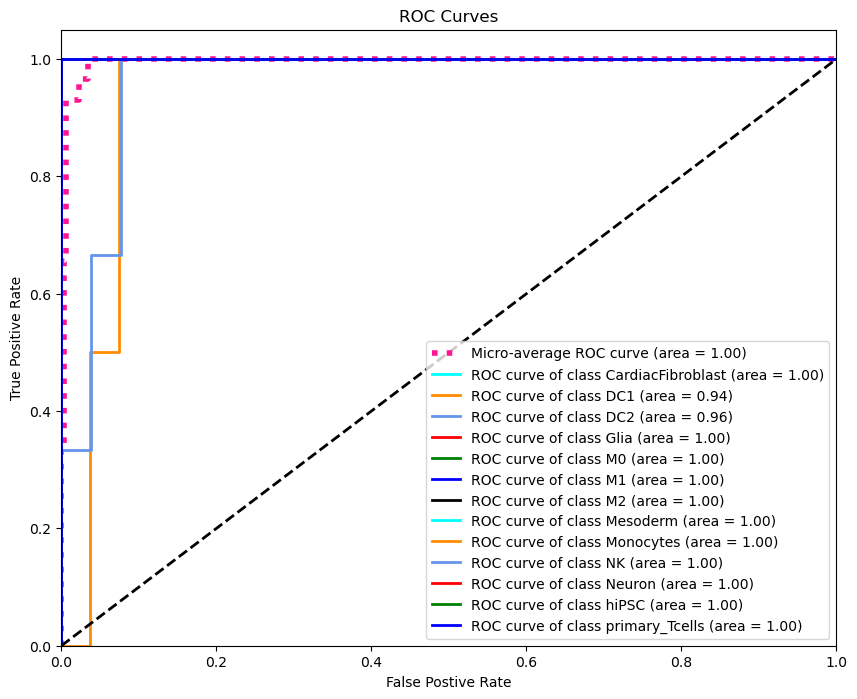

In [22]:
Randfor_RO = multiple_seeds(find_auc_rf,X_ros,y_ros,X_test,y_test)

In [23]:
save_outputs(Randfor_RO,"Randfor_RO")

# AUC of SMOTE Using Random Forest

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


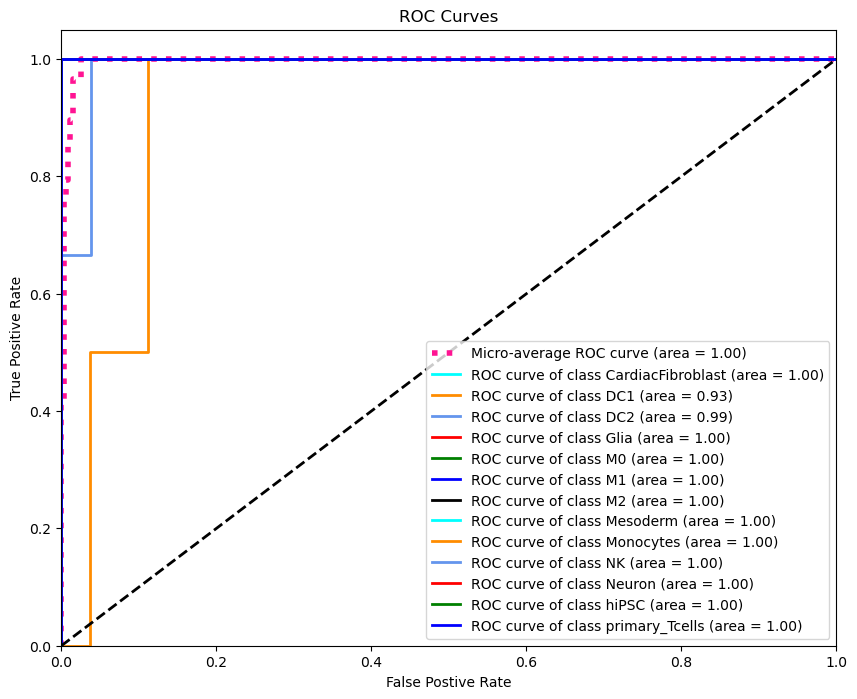

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


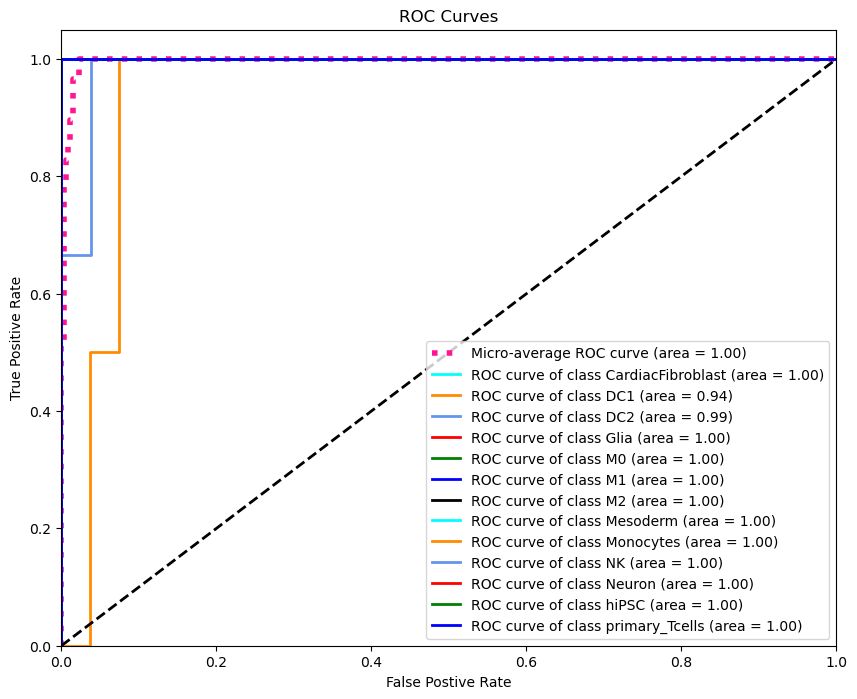

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.96
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


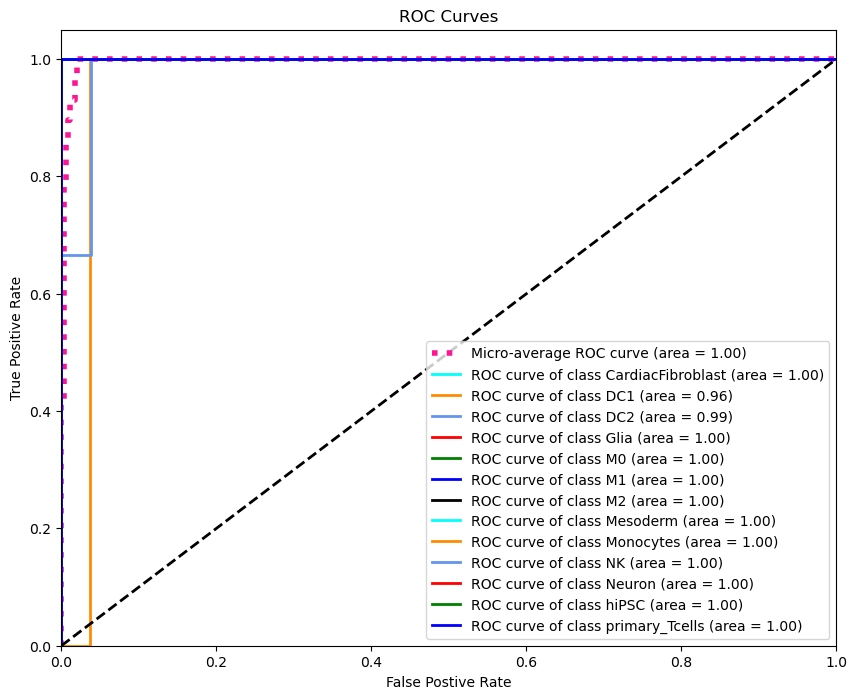

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


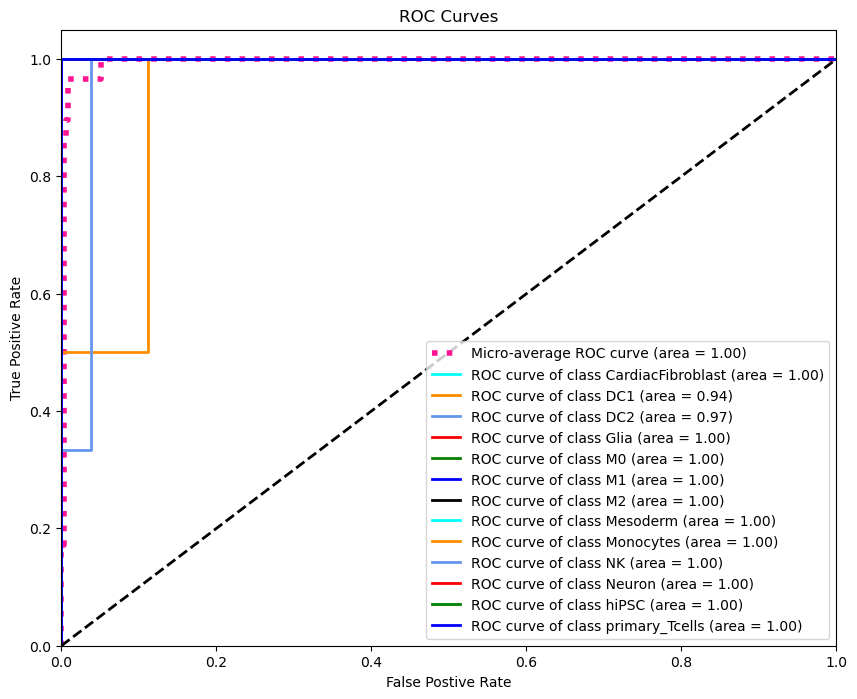

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.94
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


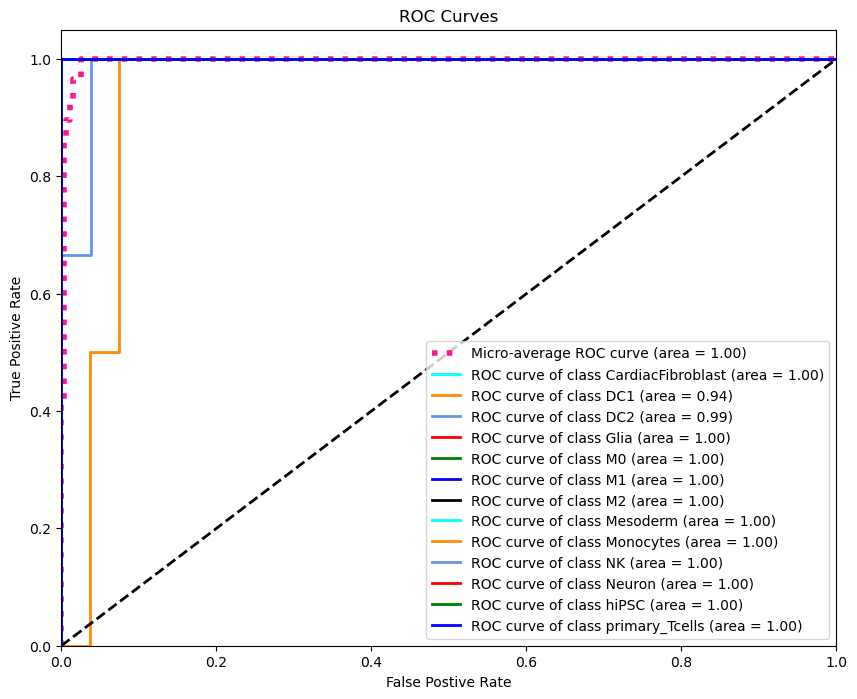

In [24]:
Randfor_SMOTE = multiple_seeds(find_auc_rf,X_SMOTE,y_SMOTE,X_test,y_test)

In [25]:
save_outputs(Randfor_SMOTE,"Randfor_SMOTE")

# AUC of BorderlineSMOTE Using Random Forest

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.89
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


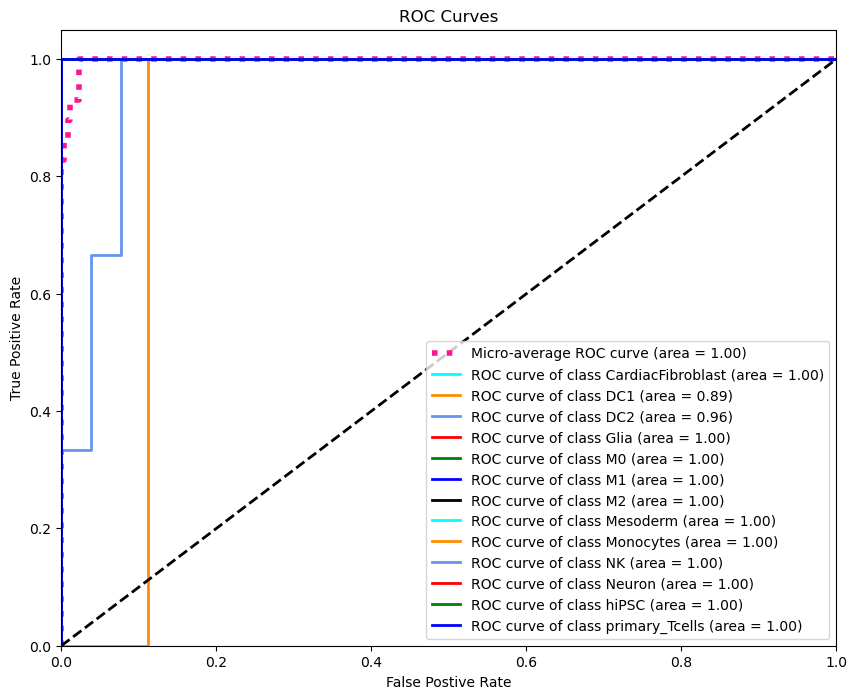

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.91
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


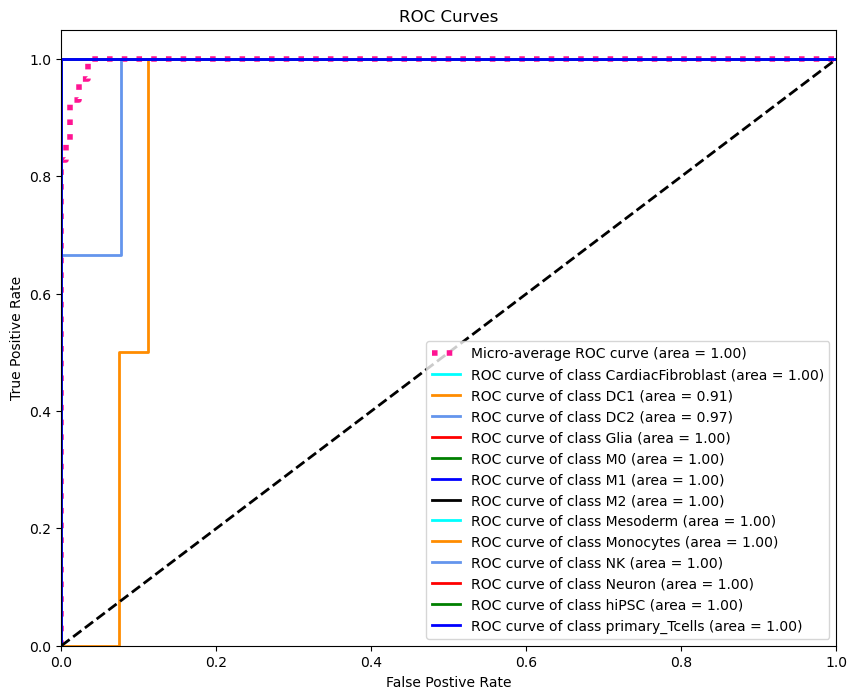

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.89
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


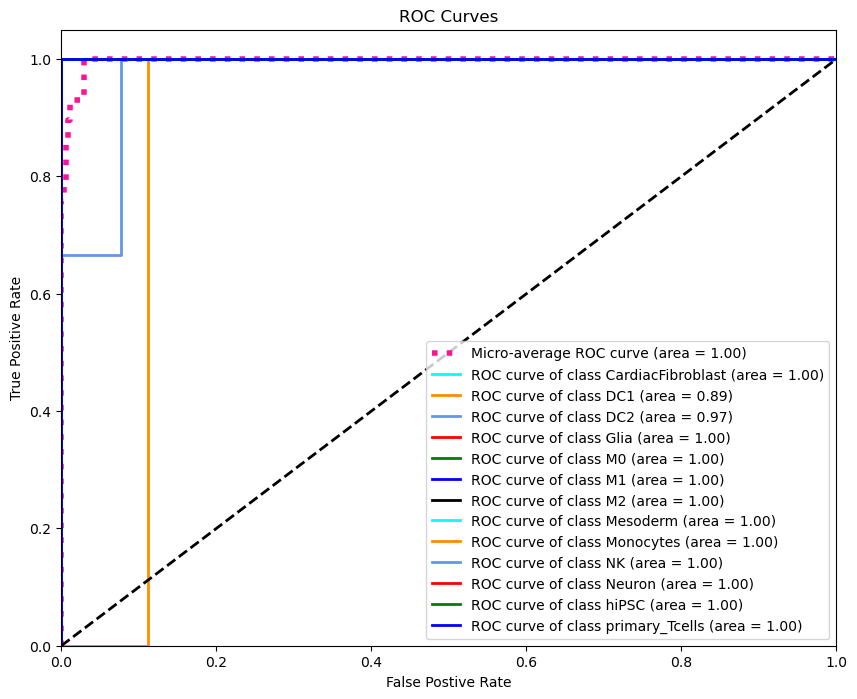

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.89
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


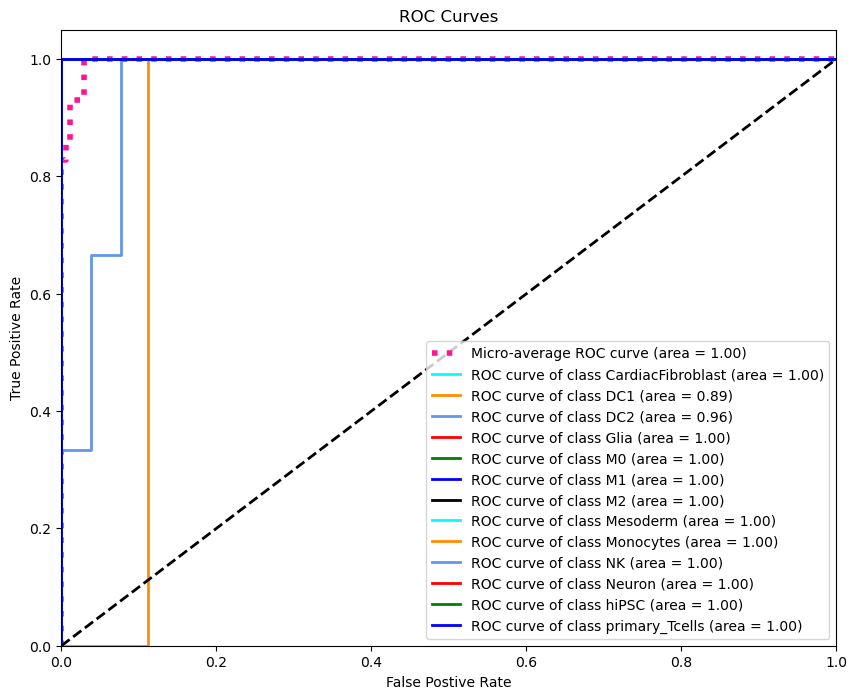

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


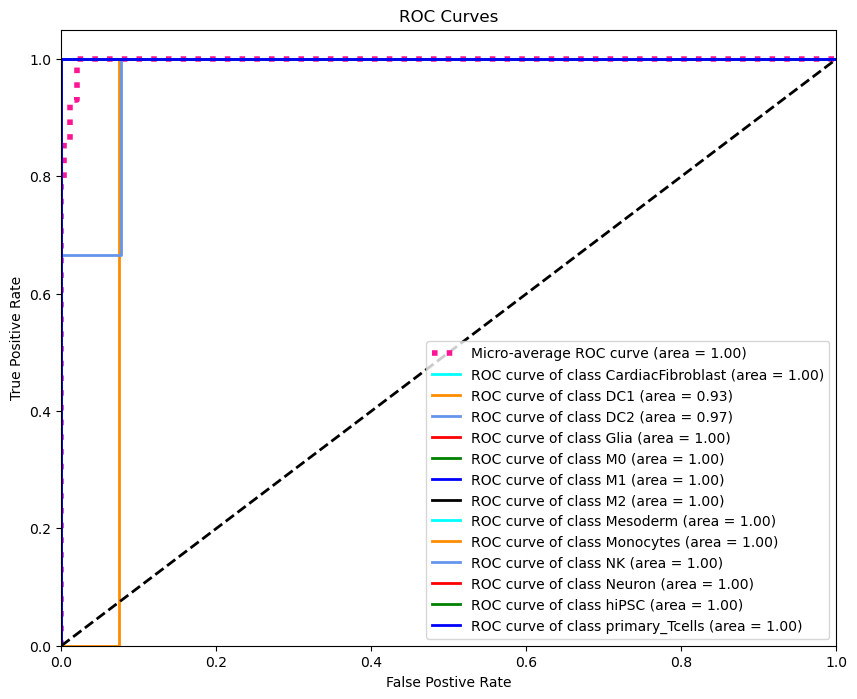

In [26]:
Randfor_BLSMOTE = multiple_seeds(find_auc_rf,X_BLSMOTE,y_BLSMOTE,X_test,y_test)

In [27]:
save_outputs(Randfor_BLSMOTE,"Randfor_BLSMOTE")

# Find AUC Score for XGBoost

In [16]:
def find_auc_XGB(X_train,y_train,X_test,y_test,rand_seed):
    xgb = XGBClassifier(
        objective = "multi:softprob",  # multiclass classification
        eval_metric = "auc", 
        random_state=rand_seed
        #learning_rate = 0.1,                      # Learning rate
        #max_depth = 6,                  # Tree depth
        #subsample = 0.8,                # Subsampling for regularization
        #colsample_bytree = 0.8,          # Feature sampling
        #n_estimators = 100
    )

    # Define the search space using skopt's space definition
    xgb_search_space = {
        'max_depth': Integer(5, 10),
        'n_estimators': Integer(100, 400),
        'learning_rate': Real(0.01, 0.3),
        'subsample': Real(0.5, 1.0),
        'colsample_bytree': Real(0.5, 1.0)
    }

    # Instantiate BayesSearchCV
    xgb_bayes = BayesSearchCV(
        estimator=xgb,
        search_spaces=xgb_search_space,
        scoring={'AUC': 'roc_auc_ovr', 'F1': 'f1_micro'},
        refit='F1',
        n_iter=10,
        cv=5,
        random_state=rand_seed,
        n_jobs=5
    )
    
    from sklearn.preprocessing import LabelEncoder
    label_encoder = LabelEncoder()
    y_train_encoded = label_encoder.fit_transform(y_train)
    y_test_encoded = label_encoder.transform(y_test)
    
    xgb_bayes.fit(X_train,y_train_encoded)
    
    cell_classes = np.unique(np.concatenate((y_train, y_test)))
    # predicted probabilities of test set
    y_probs = xgb_bayes.predict_proba(X_test)
    y_pred = xgb_bayes.predict(X_test)
    
    # Compute macro-average F1 score (treating all classes equally)
    f1_macro = f1_score(y_test_encoded, y_pred, average='macro')
    f1_weighted = f1_score(y_test_encoded, y_pred, average='weighted')
    f1_micro = f1_score(y_test_encoded,y_pred,average = 'micro')

    # Extract optimization history
    opt_df = pd.DataFrame(xgb_bayes.cv_results_)
    
    # binarize the classes
    y_test_bin = label_binarize(y_test, classes=cell_classes)
    
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_probs[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")
    
    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_probs.ravel())
    roc_auc["micro"] = auc(fpr["micro"],tpr["micro"])
    
    #plotting
    %matplotlib inline
    plt.figure(figsize = (10,8))
    lw = 2
    plt.plot(fpr["micro"],tpr["micro"],
            label = "Micro-average ROC curve (area = {0:0.2f})".format(roc_auc["micro"]),
            color = 'deeppink', linestyle = ':', linewidth=4)
    
    #cycle through colors for each class
    colors = itertools.cycle(['aqua','darkorange','cornflowerblue','red','green','blue','black'])
    for class_label, color in zip(cell_classes, colors):
        plt.plot(fpr[class_label],tpr[class_label],color=color,lw=lw,
                label='ROC curve of class {0} (area = {1:0.2f})'.format(class_label,roc_auc[class_label]))
    
    plt.plot([0,1],[0,1],'k--',lw=lw)
    plt.xlim([0.0,1.0])
    plt.ylim([0.0,1.05])
    plt.xlabel("False Postive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend(loc="lower right")
    plt.show()

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc["micro"],
    "roc_auc_per_class": roc_auc,
    "best_score": xgb_bayes.best_score_,
    "best_params": xgb_bayes.best_params_,
    "opt_history": opt_df
    }

# AUC of XGBoost with unbalanced data

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.46
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


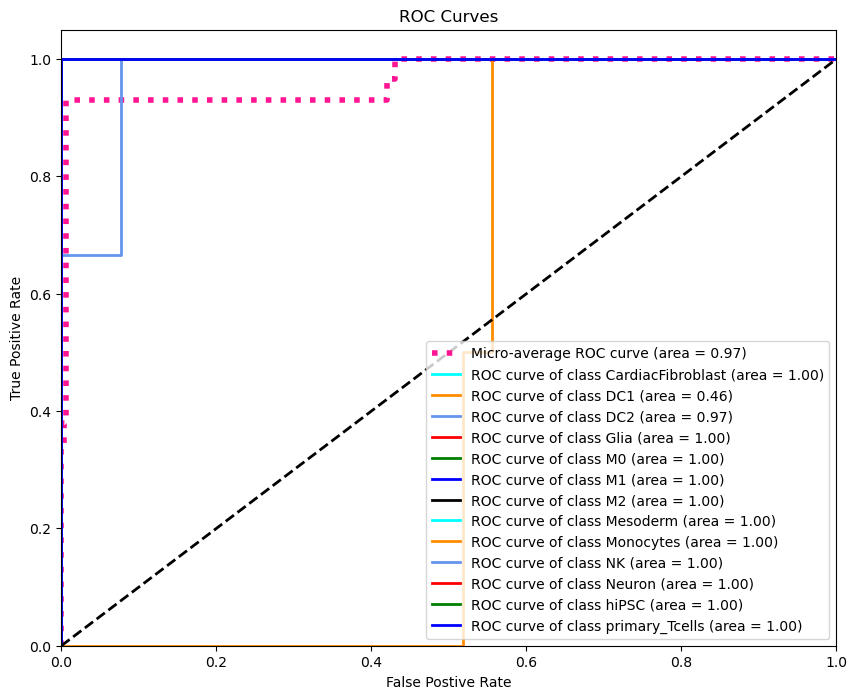

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.50
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


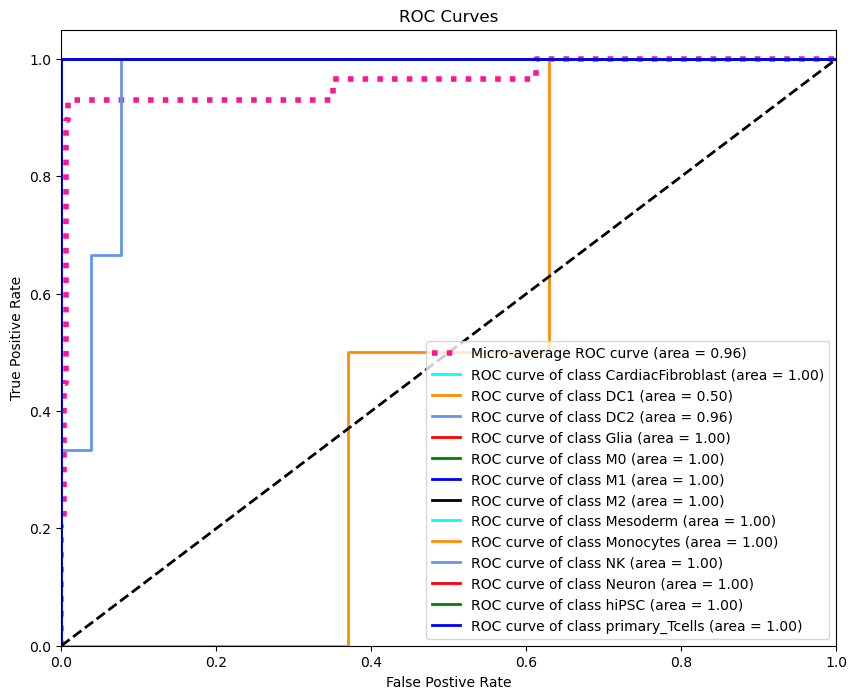

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.52
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


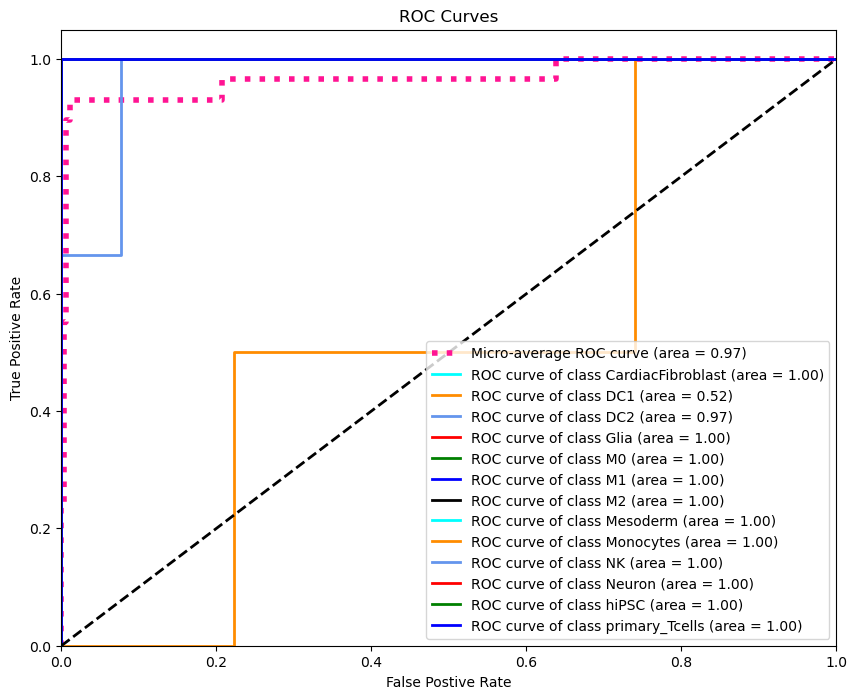

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.67
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


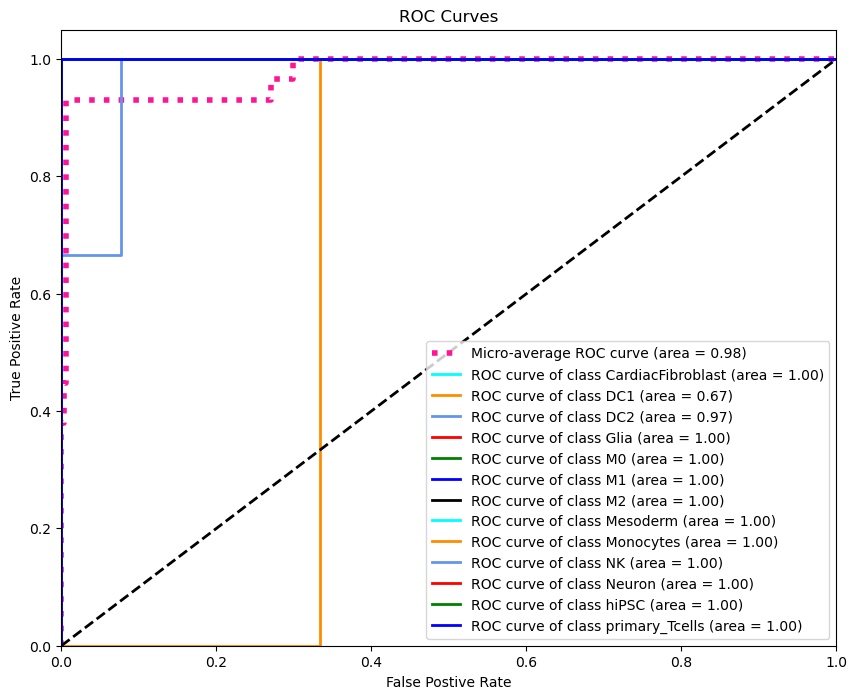

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.50
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


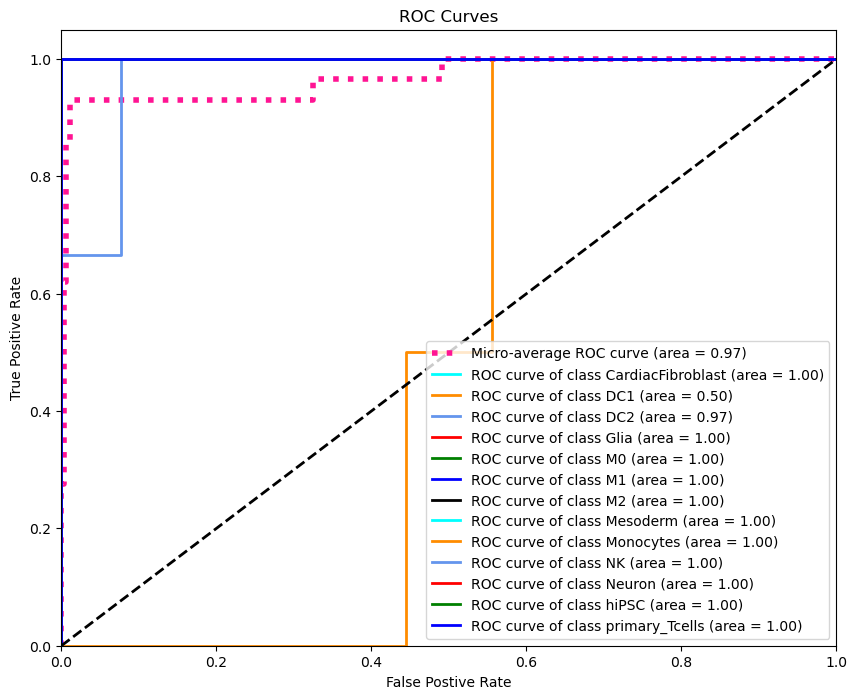

In [29]:
XGB_unbal = multiple_seeds(find_auc_XGB,X_train,y_train,X_test,y_test)

In [30]:
save_outputs(XGB_unbal,"XGB_unbal")

# AUC with Random Oversampler XGB

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.65
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


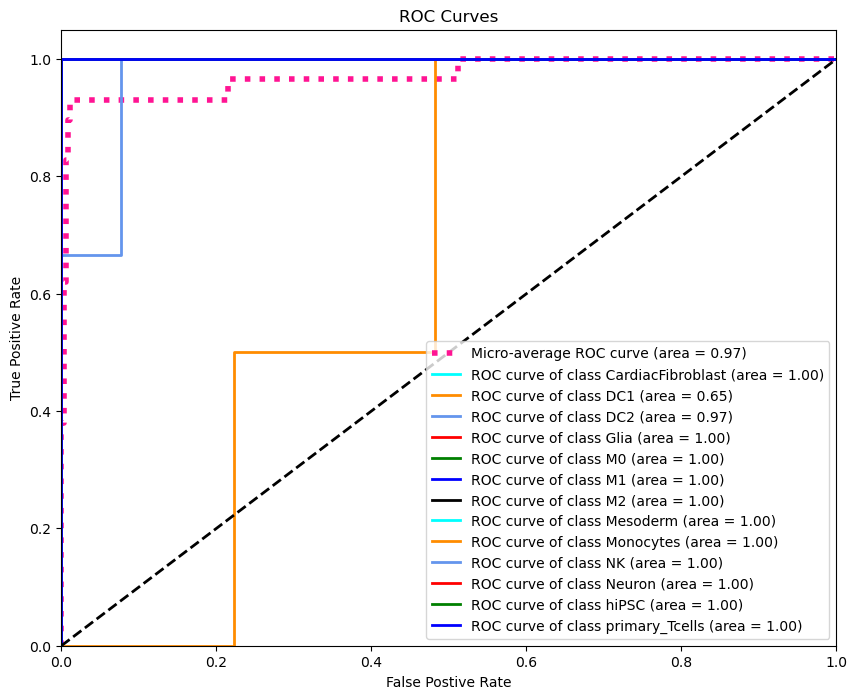

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.35
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


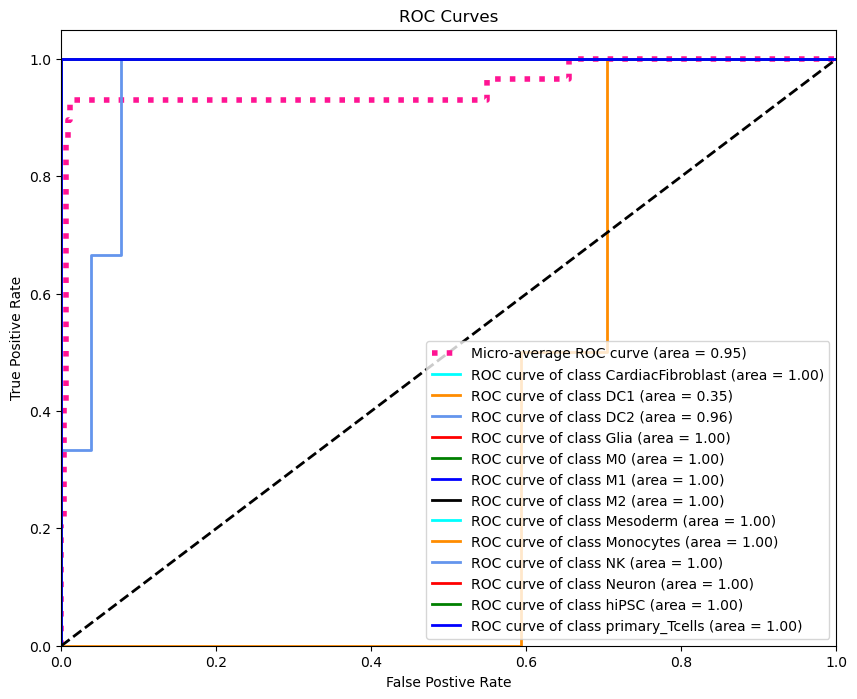

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.43
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


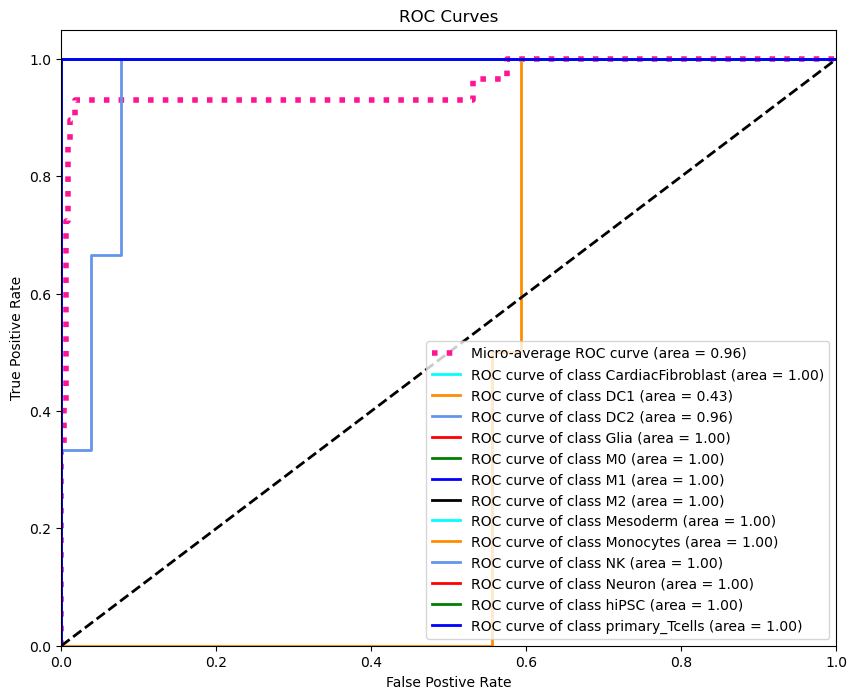

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.57
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


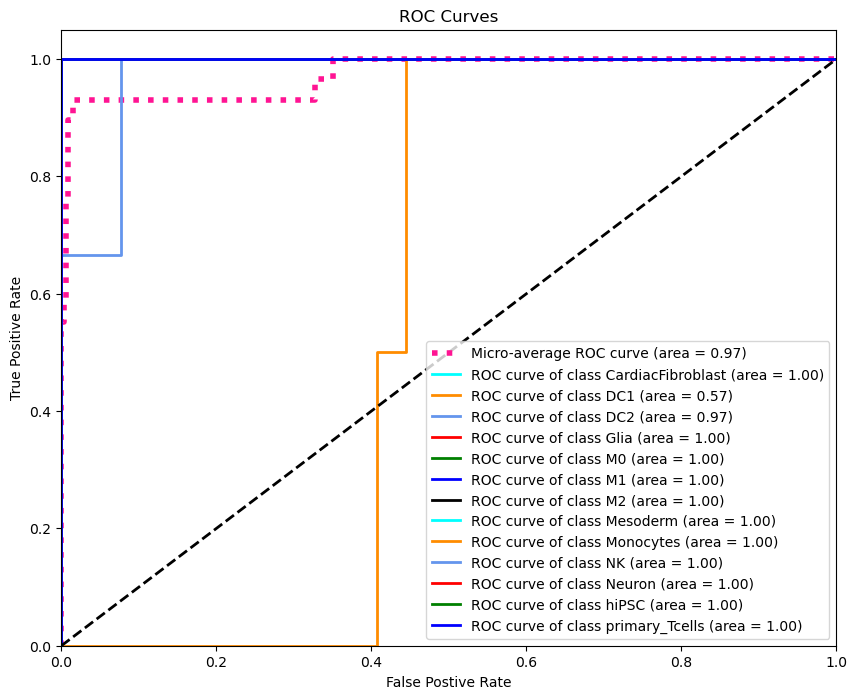

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.56
AUC for class DC2: 0.95
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


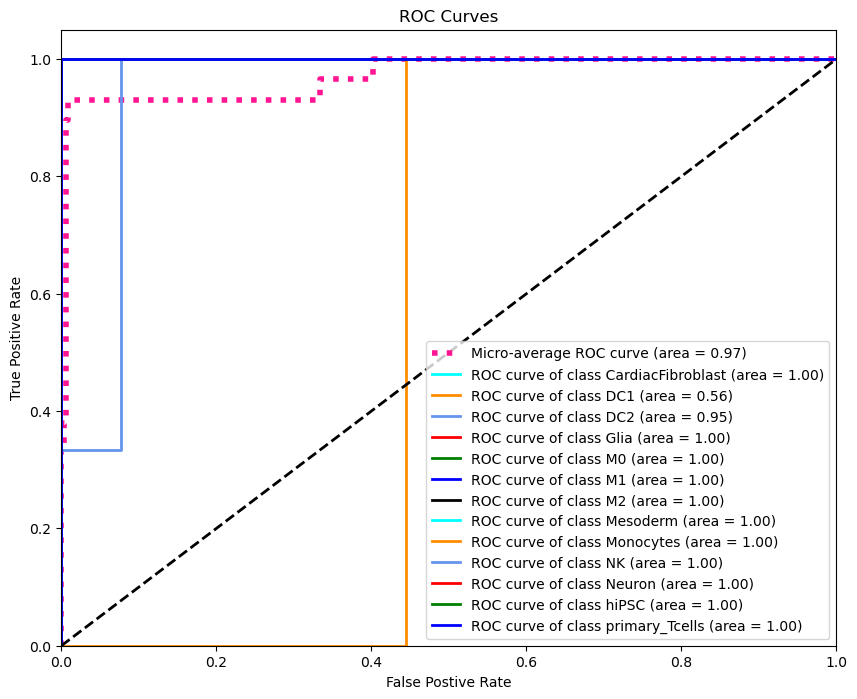

In [16]:
XGB_RO = multiple_seeds(find_auc_XGB,X_ros,y_ros,X_test,y_test)

In [17]:
save_outputs(XGB_RO,"XGB_RO")

# AUC with SMOTE and XGB

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.65
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


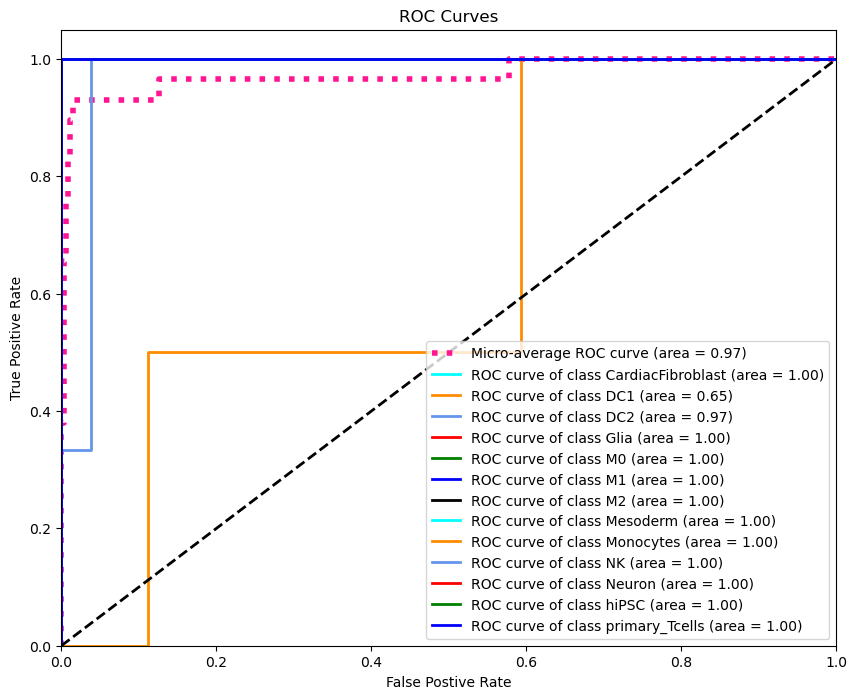

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.63
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


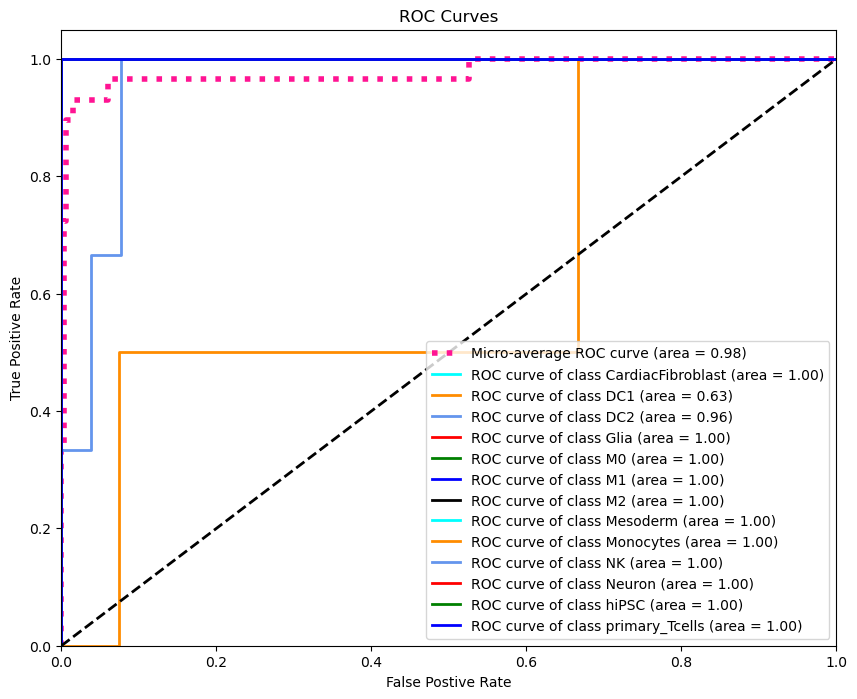

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.69
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


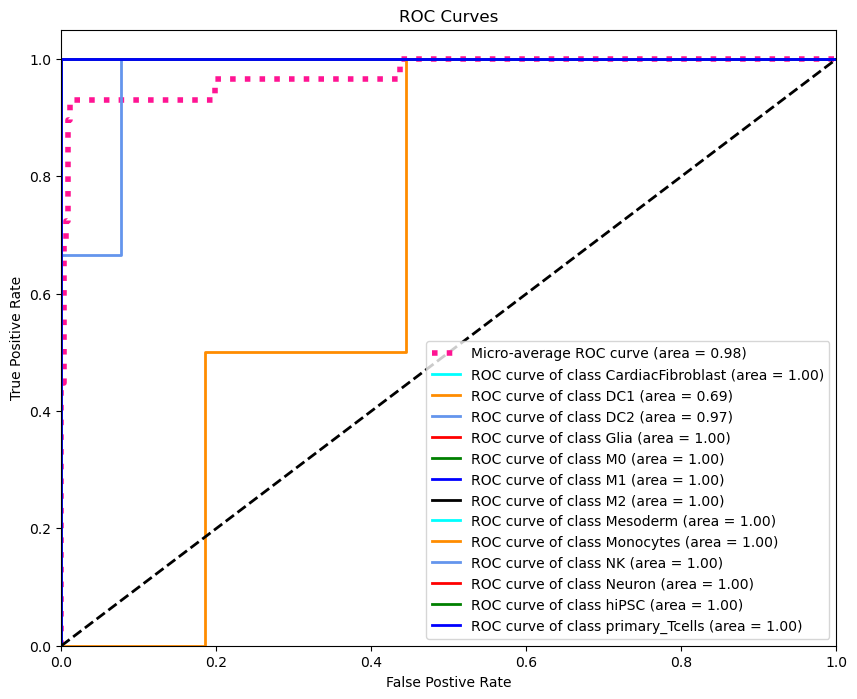

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.70
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


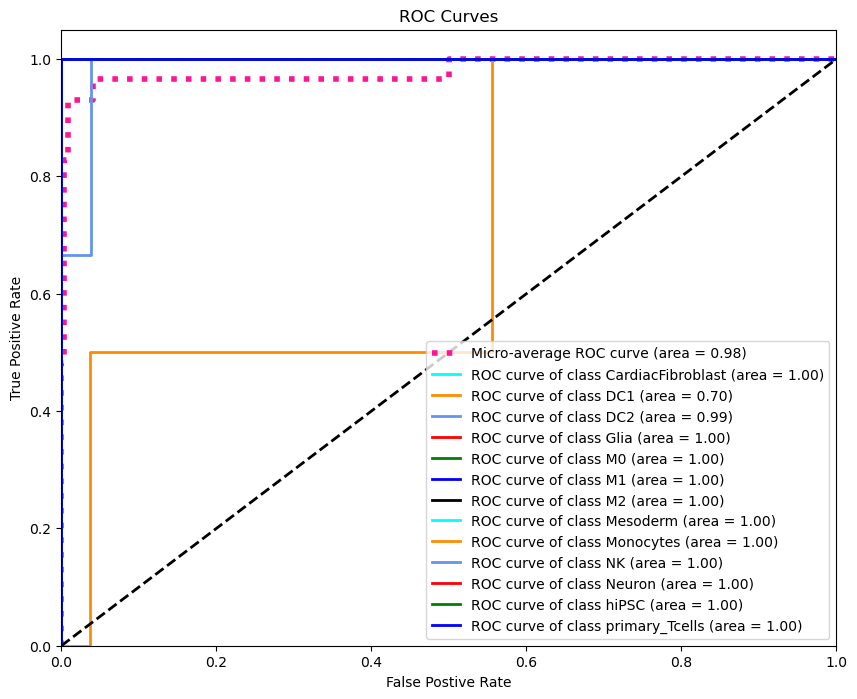

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.93
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


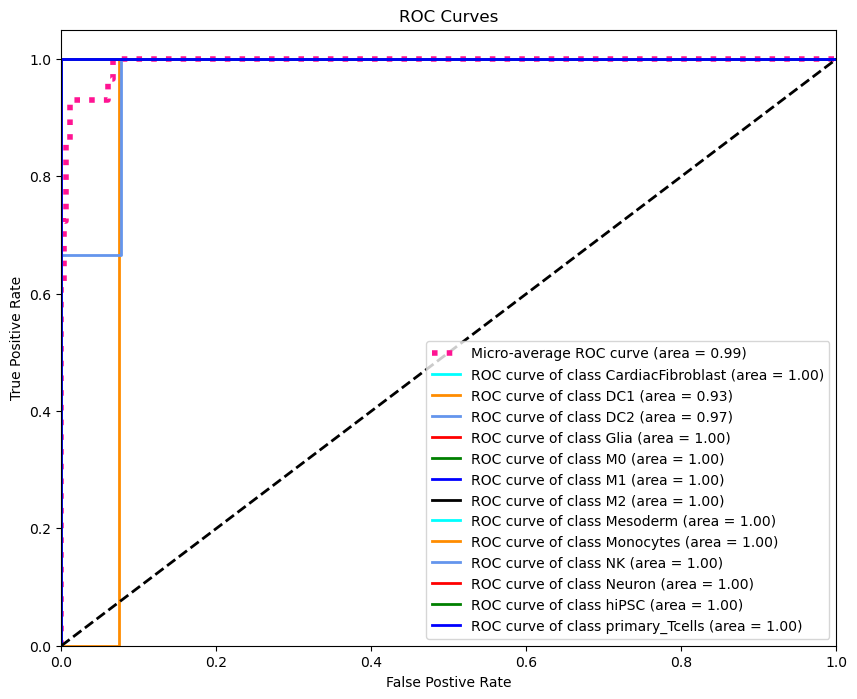

In [17]:
XGB_SMOTE = multiple_seeds(find_auc_XGB,X_SMOTE,y_SMOTE,X_test,y_test)

In [18]:
save_outputs(XGB_SMOTE,"XGB_SMOTE")

# AUC with BorderlineSMOTE and XGB

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.54
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


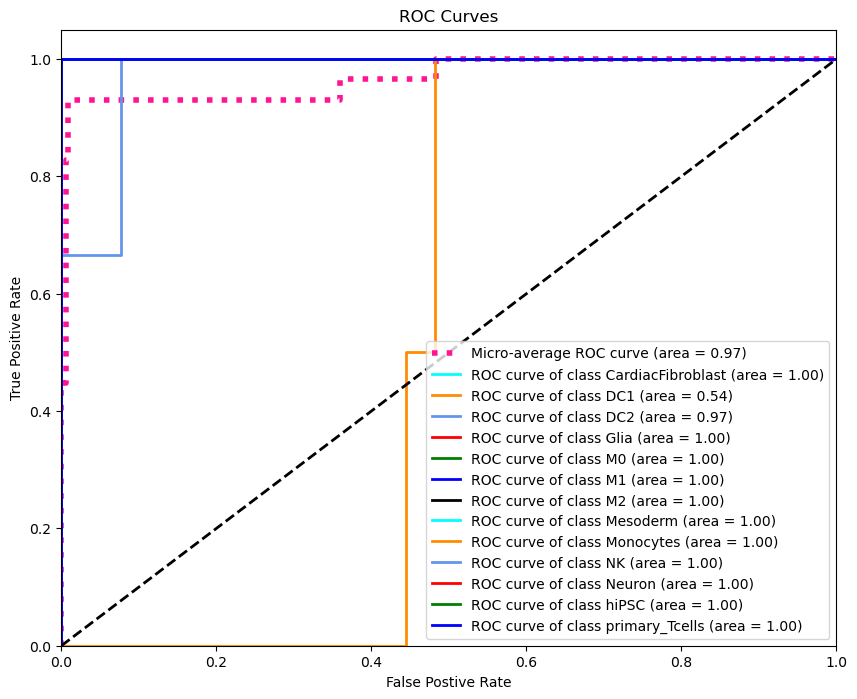

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.54
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


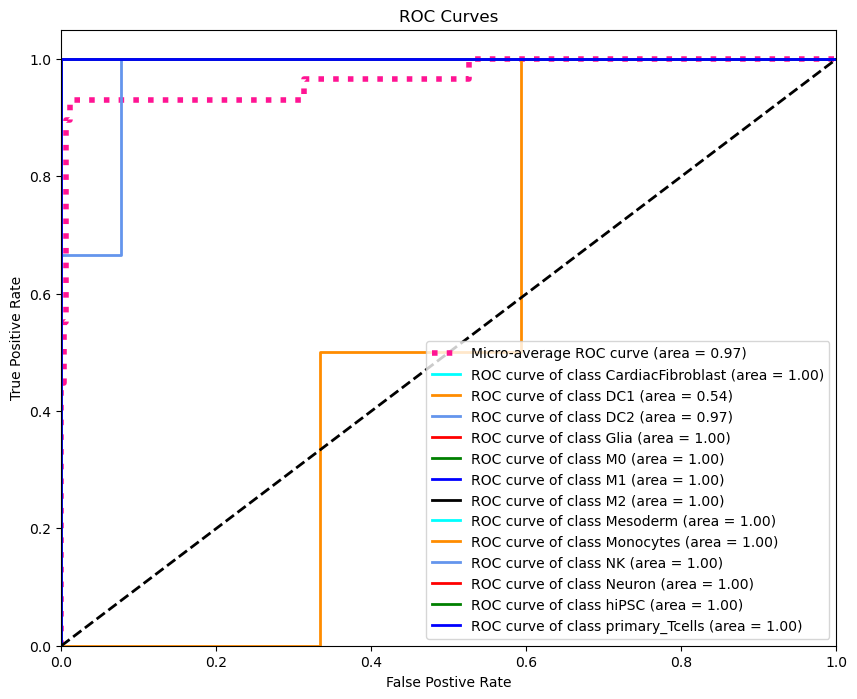

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.52
AUC for class DC2: 0.96
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


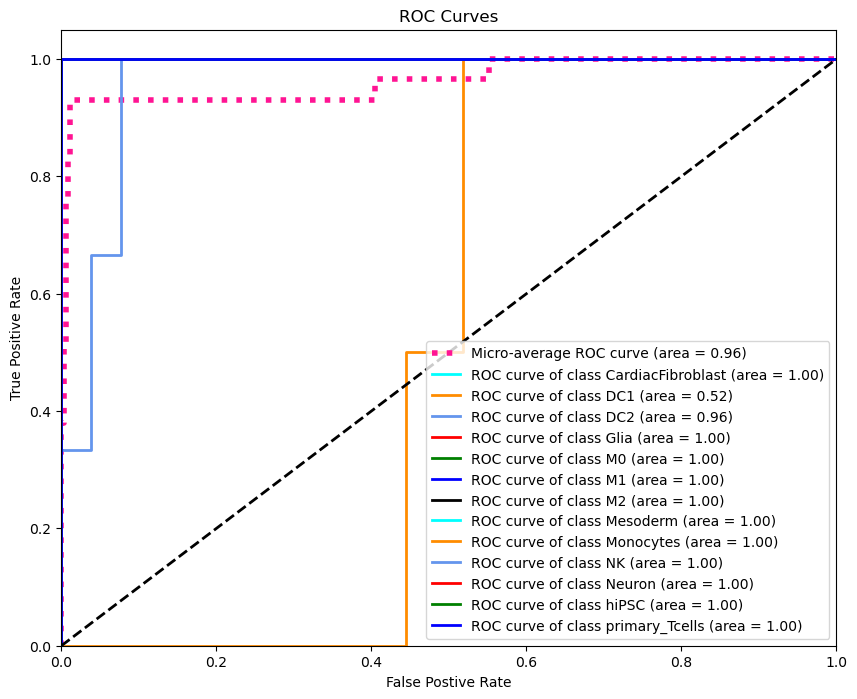

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.59
AUC for class DC2: 0.99
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


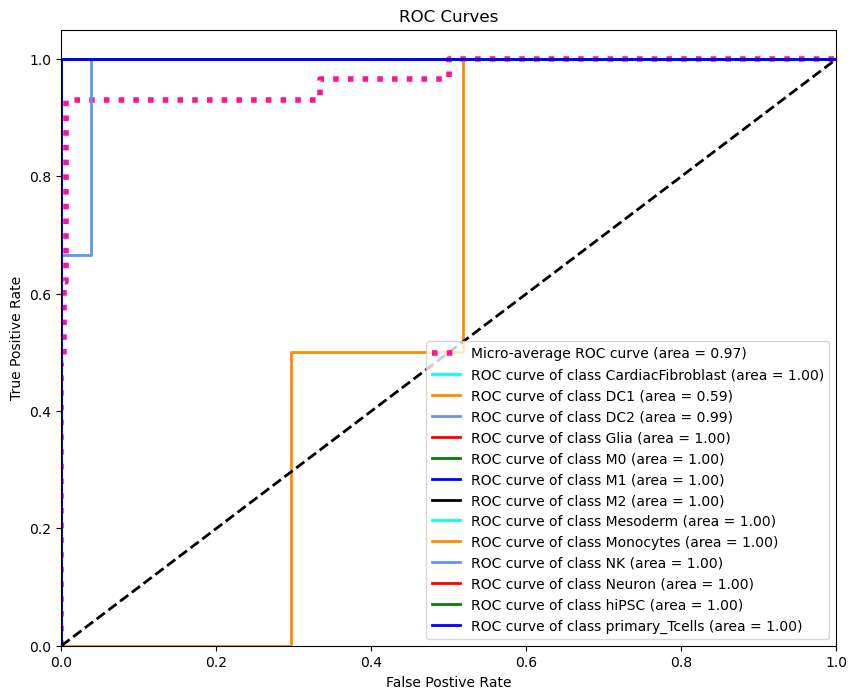

AUC for class CardiacFibroblast: 1.00
AUC for class DC1: 0.83
AUC for class DC2: 0.97
AUC for class Glia: 1.00
AUC for class M0: 1.00
AUC for class M1: 1.00
AUC for class M2: 1.00
AUC for class Mesoderm: 1.00
AUC for class Monocytes: 1.00
AUC for class NK: 1.00
AUC for class Neuron: 1.00
AUC for class hiPSC: 1.00
AUC for class primary_Tcells: 1.00


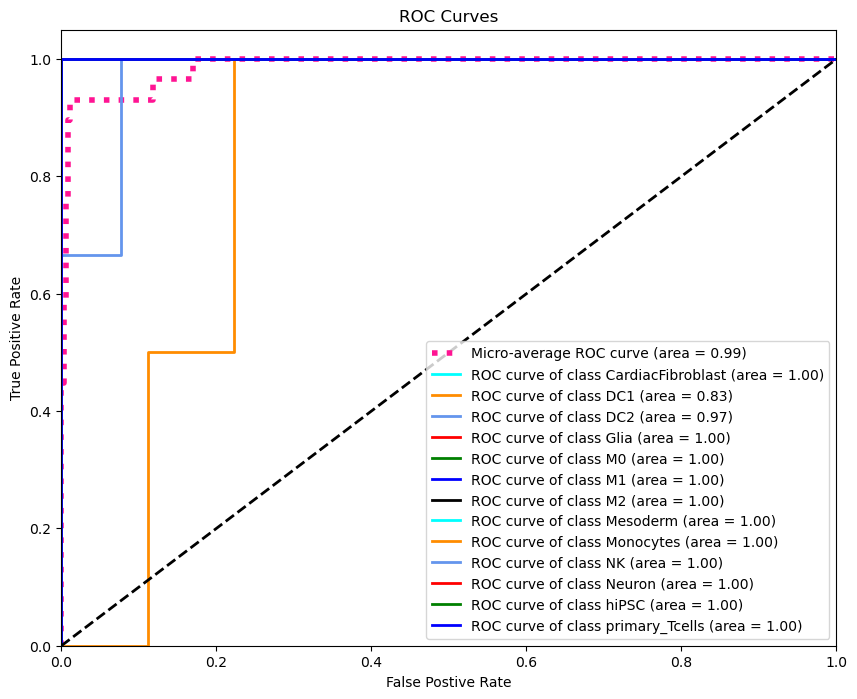

In [19]:
XGB_BLSMOTE = multiple_seeds(find_auc_XGB,X_BLSMOTE,y_BLSMOTE,X_test,y_test)

In [20]:
save_outputs(XGB_BLSMOTE,"XGB_BLSMOTE")

# Logistic Regression Feature Selection

In [2]:
def find_best_params(classifier):
    folder_path = '/scratch/by2372/pipeline/LogReg/Opt_balancing_results/'
    metrics_pattern = r"^" + classifier + ".*metrics\.csv$"
    
    metrics = {}
    
    for filename in os.listdir(folder_path):
        if re.search(metrics_pattern, filename):
            file_path = os.path.join(folder_path, filename)
            try:
                df = pd.read_csv(file_path)
                clean_name = re.sub(r"^" + classifier + "_(.*)_metrics\.csv$", r"\1", filename)
                metrics[clean_name] = df
            except Exception as e:
                print(f"Error reading file {filename}: {e}")
    
    f1_micro = {}
    f1_micro = dict.fromkeys(metrics, None)
    
    for key, value in metrics.items():
        mean_f1_micro = value.iloc[2,1:5].mean()
        max_seed = value.iloc[2,1:5].idxmax()
        f1_micro[key] = [mean_f1_micro,max_seed]
    
    best_DB = max(f1_micro, key=lambda k: f1_micro[k][0])
    best_seed = f1_micro[best_DB][1]
    best_seed_num = int("".join(filter(str.isdigit, best_seed)))
    
    param_pattern = r"^" + classifier + "_" + best_DB + "_param\.csv$"
    param = pd.DataFrame()
    
    for filename in os.listdir(folder_path):
        if re.search(param_pattern, filename):
            file_path = os.path.join(folder_path, filename)
            try:
                param = pd.read_csv(file_path)
                break
            except Exception as e:
                print(f"Error reading file {filename}: {e}")
    
    best_params_values = param.iloc[:,best_seed_num]
    best_params_keys = param.iloc[:,0]
    best_params = dict(zip(best_params_keys, best_params_values))

    return {
        "best_params": best_params,
        "best_DB": best_DB,
        "best_seed": best_seed_num,
        "f1_micro": f1_micro
    }

In [3]:
logreg_find_params = find_best_params("logreg")
logreg_best_params = logreg_find_params["best_params"]
logreg_best_DB = logreg_find_params["best_DB"]
logreg_best_seed = logreg_find_params["best_seed"]

In [4]:
logreg_find_params["f1_micro"]

{'unbal': [0.8189655172413792, 'Seed 2'],
 'BLSMOTE': [0.8706896551724137, 'Seed 2'],
 'SMOTE': [0.896551724137931, 'Seed 1'],
 'RO': [0.8620689655172413, 'Seed 1']}

In [5]:
logreg_best_seed

1

In [6]:
logreg_best_DB

'SMOTE'

In [7]:
logreg_best_params

{'C': 0.0395248983737805, 'max_iter': 377.0}

In [19]:
# L1

logreg_best_params['penalty'] = 'l1'
logreg_best_params['multi_class'] = 'multinomial'
logreg_best_params['solver'] = 'saga'
logreg_best_params['max_iter'] = int(logreg_best_params['max_iter'])
logreg_best_params['random_state'] = 3
# function must also return best_DB

# Train the logistic regression model with L1 regularization and saga solver
clf_logistic = LogisticRegression(
    **logreg_best_params
)

logreg_data_map = {
    "unbal": (X_train, y_train),
    "BLSMOTE": (X_BLSMOTE, y_BLSMOTE),
    "SMOTE": (X_SMOTE, y_SMOTE),
    "RO": (X_ros, y_ros),
}

X_logreg, y_logreg = logreg_data_map.get(logreg_best_DB, (X_train, y_train))

clf_logistic.fit(X_logreg, y_logreg)

# Extract coefficients
feature_names = np.array(TFs)
class_labels = clf_logistic.classes_

all_coefs = []

# Loop through all classes to extract coefficients
for index, class_coefs in enumerate(clf_logistic.coef_):
    class_name = class_labels[index]  # Align class name with index
    coef_df = pd.DataFrame({
        'TF': feature_names,
        'Coefficient': class_coefs,
        'cell_identity': class_name
    })
    all_coefs.append(coef_df)

# Concatenate into a single DataFrame
all_coefs_df = pd.concat(all_coefs).reset_index(drop=True)

# Save coefficients to CSV
all_coefs_df.to_csv('/scratch/by2372/pipeline/LogReg/Kall_coefs_L1.csv', index=False)


/share/apps/anaconda3/2024.02/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [20]:
logreg_best_params

{'C': 0.0395248983737805,
 'max_iter': 377,
 'penalty': 'l1',
 'multi_class': 'multinomial',
 'solver': 'saga',
 'random_state': 3}

In [21]:
# Load the coefficients CSV as a DataFrame. ONLY IF STARTING AFTER COEFFICIENT CSV WAS GENERATED. If not, comment out.
file_path = "/scratch/by2372/pipeline/LogReg/Kall_coefs_L1.csv"
all_coefs_df = pd.read_csv(file_path)
#all_coefs_df.loc[all_coefs_df['cell_identity'] == 'm0', 'cell_identity'] = 'ipscderived_m0' # Relabeling ipsc derived M0 macrophage samples which were originally labeled m0 to be more accurate


# Initializing an empty df for the tfs with the highest coefficients for each cell type
strongest_tfs = pd.DataFrame()

# Iterating through each cell type for the top 10 TFs ranked by coefficients and printing the results
for cell in all_coefs_df['cell_identity'].unique():
    subset = all_coefs_df[all_coefs_df['cell_identity'] == cell]
    sorted_subset = subset.sort_values(by='Coefficient', ascending=False)

    #get the 10 at the head and tail
    top_tfs = sorted_subset.head(10)
    strongest_tfs = pd.concat([strongest_tfs, top_tfs], ignore_index=True)


    print(f"Top 10 TFs for {cell}:")
    print(top_tfs)
    print("\n")


Top 10 TFs for CardiacFibroblast:
                             TF  Coefficient      cell_identity
5105     NME2_ENST00000512737.6     0.001371  CardiacFibroblast
1382    DRAP1_ENST00000312515.7     0.001344  CardiacFibroblast
307      ATF4_ENST00000674920.3     0.000888  CardiacFibroblast
14      AEBP1_ENST00000223357.8     0.000736  CardiacFibroblast
8558    YBX1_ENST00000332220.10     0.000732  CardiacFibroblast
2575    HIF1A_ENST00000337138.9     0.000620  CardiacFibroblast
904   CREB3L1_ENST00000621158.5     0.000535  CardiacFibroblast
6263    PRRX2_ENST00000372469.6     0.000423  CardiacFibroblast
8442   TWIST2_ENST00000612363.2     0.000293  CardiacFibroblast
8444   TWIST2_ENST00000673387.1     0.000293  CardiacFibroblast


Top 10 TFs for DC1:
                             TF  Coefficient cell_identity
15508   GTF3A_ENST00000482655.2     0.000924           DC1
21431  TRAFD1_ENST00000412615.7     0.000868           DC1
13489   BATF3_ENST00000471382.5     0.000854           DC1
2160

# Random Forest Feature Selection

In [22]:
randfor_find_params = find_best_params("Randfor")
randfor_best_params = randfor_find_params["best_params"]
randfor_best_DB = randfor_find_params["best_DB"]
randfor_best_seed = randfor_find_params["best_seed"]

randfor_best_params['criterion'] = "gini"
randfor_best_params['bootstrap'] = True
randfor_best_params['n_estimators'] = int(randfor_best_params['n_estimators'])
randfor_best_params['max_depth'] = int(randfor_best_params['max_depth'])
randfor_best_params['random_state'] = 3

randfor_data_map = {
    "unbal": (X_train, y_train),
    "BLSMOTE": (X_BLSMOTE, y_BLSMOTE),
    "SMOTE": (X_SMOTE, y_SMOTE),
    "RO": (X_ros, y_ros),
}

X_randfor, y_randfor = randfor_data_map.get(randfor_best_DB, (X_train, y_train))

In [23]:
randfor_best_seed

1

In [24]:
randfor_best_DB

'unbal'

In [25]:
randfor_best_params

{'max_depth': 8,
 'max_features': 0.7696216890044109,
 'n_estimators': 155,
 'criterion': 'gini',
 'bootstrap': True,
 'random_state': 3}

In [26]:
def rf_feature_selection(X_train,y_train,cell_type,TF_names,randfor_best_params):
    
    y_train_new = [1 if x == cell_type else 0 for x in y_train]

    # Train Random Forest
    rf = RandomForestClassifier(
            **randfor_best_params
        )
    rf.fit(X_train,y_train_new)

    importances = rf.feature_importances_
    importances_df = pd.DataFrame({'Feature': TF_names, 'Importance': importances})

    # Rank features by importance
    importances_df = importances_df.sort_values(by='Importance', ascending=False).reset_index()

    # Select top N features (example selecting top 10 features)
    top_TFs = importances_df[:10]
    print(f"Top 10 TFs for {cell_type}:")
    print(top_TFs)
    print("\n")



# M0, M1, M2 Top Features with Random Forest

In [27]:
rf_feature_selection(X_randfor,y_randfor,"M0",TFs,randfor_best_params)

Top 10 TFs for M0:
   index                    Feature  Importance
0  10503  ZNF385A_ENST00000394313.7    0.153865
1   4224   MLXIPL_ENST00000434326.5    0.096178
2  11564   ZNF580_ENST00000543039.2    0.090323
3   4227   MLXIPL_ENST00000467221.1    0.045161
4     56    AHRR_ENST00000316418.10    0.032258
5   9791   ZNF219_ENST00000553296.1    0.032258
6   8854   ZBTB48_ENST00000319084.9    0.025806
7   1611      ERF_ENST00000595941.1    0.019355
8    195   ARID3A_ENST00000590749.2    0.019355
9   6958      SKI_ENST00000508416.1    0.019355




In [28]:
rf_feature_selection(X_randfor,y_randfor,"M1",TFs,randfor_best_params)

Top 10 TFs for M1:
   index                  Feature  Importance
0    434  BATF2_ENST00000301887.9    0.464516
1   7471  STAT2_ENST00000555488.2    0.070968
2   3031   IRF1_ENST00000245414.9    0.070968
3   3186   IRF7_ENST00000621391.4    0.057204
4   7429  STAT1_ENST00000392322.7    0.056117
5   7455  STAT1_ENST00000674080.1    0.048653
6   7440  STAT1_ENST00000673638.1    0.019355
7   3050   IRF1_ENST00000679743.1    0.016838
8   7452  STAT1_ENST00000673942.1    0.012903
9   3032   IRF1_ENST00000405885.6    0.012903




In [29]:
rf_feature_selection(X_randfor,y_randfor,"M2",TFs,randfor_best_params)

Top 10 TFs for M2:
   index                    Feature  Importance
0   1189     DLX1_ENST00000709710.1    0.167742
1   1183     DLX1_ENST00000361609.4    0.167742
2   6614   RHOXF2_ENST00000371388.5    0.154839
3   6613  RHOXF2B_ENST00000371402.5    0.154839
4   1191     DLX1_ENST00000709712.1    0.025806
5   1184     DLX1_ENST00000361725.5    0.025806
6  11076   ZNF506_ENST00000587452.5    0.019355
7   6291     RARA_ENST00000577646.5    0.012903
8   7082    SMYD3_ENST00000482592.5    0.012903
9   4210     MITF_ENST00000693031.1    0.012903




# XGBoost Feature Selection

In [30]:
XGB_find_params = find_best_params("XGB")
XGB_best_params = XGB_find_params["best_params"]
XGB_best_DB = XGB_find_params["best_DB"]
XGB_best_seed = XGB_find_params["best_seed"]

XGB_best_params['objective'] = "binary:logistic"
XGB_best_params['eval_metric'] = "auc"
XGB_best_params['n_estimators'] = int(XGB_best_params['n_estimators'])
XGB_best_params['max_depth'] = int(XGB_best_params['max_depth'])
XGB_best_params['random_state'] = 5

#Hard coded XGB params from seed 4 to see if feature selection worked better; seed 4 had identical best F1 to Seed 2
#XGB_best_params['colsample_bytree'] = 0.5824331345829631
#XGB_best_params['learning_rate'] =0.09973280770414338
#XGB_best_params['max_depth'] = 6
#XGB_best_params['n_estimators'] = 383
#XGB_best_params['subsample'] = 0.5627180936430249

XGB_data_map = {
    "unbal": (X_train, y_train),
    "BLSMOTE": (X_BLSMOTE, y_BLSMOTE),
    "SMOTE": (X_SMOTE, y_SMOTE),
    "RO": (X_ros, y_ros),
}

X_XGB, y_XGB = XGB_data_map.get(XGB_best_DB, (X_train, y_train))

In [31]:
XGB_best_seed

1

In [32]:
XGB_best_DB

'BLSMOTE'

In [33]:
XGB_best_params

{'colsample_bytree': 0.7097275061832551,
 'learning_rate': 0.0635809799837911,
 'max_depth': 8,
 'n_estimators': 394,
 'subsample': 0.6653523747252599,
 'objective': 'binary:logistic',
 'eval_metric': 'auc',
 'random_state': 5}

In [34]:
def xgb_feature_selection(X_train,y_train,cell_type,TF_names,XGB_best_params):

    y_train_new = [1 if x == cell_type else 0 for x in y_train]
    
    xgb = XGBClassifier(
        **XGB_best_params
    )
    
    xgb.fit(X_train,y_train_new)
    
    importances = xgb.get_booster().get_score(importance_type="gain")
    # Convert feature indices ('f12', 'f56', etc.) to integer indices
    feature_importance = {
        int(k[1:]): v for k, v in importances.items()
    }
    
    # Create a DataFrame with the actual feature names
    importances_df = pd.DataFrame({
        'Feature': [TF_names[i] for i in feature_importance.keys()],
        'Gain': feature_importance.values()
    })
    
    # Rank features by importance
    importances_df = importances_df.sort_values(by='Gain', ascending=False).reset_index()
    
    # Select top N features (example selecting top 10 features)
    top_TFs = importances_df[:10]
    print(f"Top 10 TFs for {cell_type}:")
    print(top_TFs)
    print("\n")

In [35]:
xgb_feature_selection(X_XGB,y_XGB,"M0",TFs,XGB_best_params)

Top 10 TFs for M0:
   index                    Feature       Gain
0      2    CXXC1_ENST00000590901.5  38.397789
1      6    NR1H3_ENST00000436778.5  24.702980
2     11  ZNF385A_ENST00000394313.7  17.956564
3      8   ZNF207_ENST00000579810.2   6.724392
4     10   ZNF219_ENST00000553296.1   6.598652
5     12   ZNF580_ENST00000543039.2   6.196919
6      0   ARID3A_ENST00000590749.2   5.834852
7      5    NFAT5_ENST00000426654.6   5.624715
8      3   MLXIPL_ENST00000434326.5   5.429313
9      7   ZBTB48_ENST00000466941.1   2.702159




In [36]:
xgb_feature_selection(X_XGB,y_XGB,"M1",TFs,XGB_best_params)

Top 10 TFs for M1:
   index                  Feature       Gain
0     10  STAT2_ENST00000555488.2  48.507118
1      1   IRF1_ENST00000245414.9  22.419920
2      5  STAT1_ENST00000392322.7  22.186546
3      0  BATF2_ENST00000301887.9   9.169183
4      9  STAT1_ENST00000674153.1   8.542993
5      6  STAT1_ENST00000673638.1   8.026158
6      2   IRF1_ENST00000405885.6   2.650269
7      7  STAT1_ENST00000673942.1   1.679281
8      3   IRF7_ENST00000621391.4   1.061514
9      4  NR1H3_ENST00000530310.1   0.920194




In [37]:
xgb_feature_selection(X_XGB,y_XGB,"M2",TFs,XGB_best_params)

Top 10 TFs for M2:
   index                    Feature       Gain
0      5  RHOXF2B_ENST00000371402.5  29.664526
1      1     DLX1_ENST00000709710.1  14.209885
2      0     DLX1_ENST00000361609.4   8.513609
3      2    ESRRG_ENST00000361395.6   4.886315
4      6   RHOXF2_ENST00000371388.5   3.030801
5      4     RARA_ENST00000577646.5   0.896282
6      8   ZNF430_ENST00000597922.1   0.889629
7      7   ZNF283_ENST00000593268.5   0.722884
8      3    HIF1A_ENST00000553999.5   0.648442


